<a href="https://colab.research.google.com/github/saskiaalifah/SaskiaAlifah_2411531002_BigData26/blob/main/Praktikum4/BD_P04_2411531002_SaskiaAlifah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL PRAKTIKUM BIG DATA — PRAKTIKUM 4 · S1 INFORMATIKA
## NoSQL dan Pemodelan Data · Durasi 120 menit



## K. Tutorial Langkah demi Langkah

### K-1. Menyiapkan Lingkungan dan Data Contoh
**Tujuan.** Memasang pustaka, membaca `trips_bersih/`, dan mengganti nama kolom menjadi nama yang mudah dibaca. Sel pertama khusus Colab; sel kedua berlaku di mana saja.

`trips_bersih/` asli dari Praktikum 3 dibaca per file Parquet dengan PyArrow, lalu nilai `wilayah_jemput` diambil dari nama folder partisi (`borough_naik=...`), tidak dengan satu `pd.read_parquet()` pada seluruh folder. Hasilnya tetap sebuah `df` dengan nama kolom baru seperti pada modul. **Jalur cadangan K-1b (data tiruan) tidak dipakai**: seluruh percobaan memakai data taksi asli, kecuali titik pada K-6 yang memang tiruan sesuai modul.

In [ ]:
!pip install -q duckdb networkx shapely tinydb "deltalake>=1.0"
from google.colab import drive
drive.mount("/content/drive")
DIR_P3 = "/content/drive/MyDrive/BigData/Praktikum3"
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum4"
TRIPS_BERSIH = f"{DIR_P3}/trips_bersih" # hasil Praktikum 3 (K-10)
import os
os.makedirs(DIR_SIMPAN, exist_ok=True)
assert os.path.exists(TRIPS_BERSIH), "Folder trips_bersih/ tidak ada. Jalankan ulang P3/K-10 atau pakai K-1b."

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, time, json, sqlite3, random, shutil, glob
import numpy as np, pandas as pd
import pyarrow.parquet as pq

# Pengukur waktu (dari Praktikum 1/K-3, versi ringkas)
catatan = []
def ukur(label, fungsi):
    t0 = time.perf_counter()
    hasil = fungsi()
    detik = time.perf_counter() - t0
    catatan.append({"langkah": label, "detik": round(detik, 4)})
    print(f"[{label}] {detik:.4f} s")
    return hasil


# Membaca trips_bersih
def baca_trips_bersih():
    files = glob.glob(
        os.path.join(TRIPS_BERSIH, "**", "*.parquet"),
        recursive=True
    )

    print("Jumlah file Parquet:", len(files))

    dfs = []

    for f in files:
        # Baca file Parquet secara langsung,
        # tanpa membaca partisi dari struktur folder
        temp = pq.ParquetFile(f).read().to_pandas()

        # Ambil wilayah dari nama folder
        folder = os.path.basename(os.path.dirname(f))
        wilayah = folder.replace("borough_naik=", "")
        wilayah = wilayah.replace("%20", " ")

        # Folder default tetap dipertahankan
        if wilayah == "":
            wilayah = "Unknown"

        temp["borough_naik"] = wilayah
        dfs.append(temp)

    return pd.concat(dfs, ignore_index=True)


df = ukur("baca trips_bersih", baca_trips_bersih)


# Ganti nama kolom asli data TLC menjadi nama yang lebih mudah dibaca
NAMA_BARU = {
    "tpep_pickup_datetime": "waktu_jemput",
    "PULocationID": "zona_jemput",
    "DOLocationID": "zona_tujuan",
    "borough_naik": "wilayah_jemput",
    "trip_distance": "jarak_mil",
    "total_amount": "total_bayar",
    "tip_amount": "tip",
    "nama_pembayaran": "metode_bayar",
}

df = df.rename(columns=NAMA_BARU)
df["wilayah_jemput"] = df["wilayah_jemput"].astype(str)

print("baris:", f"{len(df):,}", "| kolom:", df.shape[1])


# Contoh 300.000 baris untuk K-2 dan K-3
sample = df.sample(
    n=min(300_000, len(df)),
    random_state=42
).reset_index(drop=True)

sample["id_perjalanan"] = sample.index + 1
sample["waktu_jemput"] = sample["waktu_jemput"].astype(str)

Jumlah file Parquet: 8
[baca trips_bersih] 3.6770 s
baris: 2,986,910 | kolom: 18


**Interpretasi K-1.** `trips_bersih/` asli terbaca dari **8 file Parquet** dalam **3,6770 s**: **2.986.910 baris** dan **18 kolom**. Contoh pada modul memakai 1.000.000 baris dan 15 kolom, jadi data saya hampir **3 kali lebih banyak baris** dan 3 kolom lebih banyak. Karena itu waktu pada percobaan berikutnya cenderung lebih besar daripada contoh modul, dan besaran perbandingannya bisa berbeda; yang dibandingkan di bawah selalu angka hasil ukur saya sendiri pada data asli ini.

### K-2. Tabel Biasa vs Key-value
**Tujuan.** Menyimpan perjalanan yang sama dalam dua cara, lalu mengajukan dua pertanyaan berbeda. Cara pertama: tabel SQLite. Cara kedua: key-value, yaitu kamus Python yang kuncinya “perjalanan:&lt;id&gt;” dan nilainya teks JSON.

**Dugaan saya (ditulis sebelum menjalankan):**
- Pencarian satu id: tabel SQLite **tanpa indeks** paling lambat, kira-kira **500–2.000 kali** lebih lambat daripada tabel berindeks. Tabel **berindeks** dan **key-value** hampir sama cepat (selisih paling banyak 2–5 kali).
- Menghitung rata-rata per wilayah: key-value **5–8 kali lebih lambat** daripada SQL `GROUP BY`, karena setiap nilai harus dibuka dulu (`json.loads`).

In [ ]:
KOLOM = ["id_perjalanan", "waktu_jemput", "zona_jemput", "zona_tujuan",
         "wilayah_jemput", "jarak_mil", "total_bayar", "metode_bayar"]
data = sample[KOLOM].copy()

# Model 1 - relasional: tabel SQLite
if os.path.exists("uji.db"):
    os.remove("uji.db")
con = sqlite3.connect("uji.db")
ukur("relasional: muat tabel", lambda: data.to_sql("perjalanan", con, index=False))

# Model 2 - key-value: kamus (dict) dengan kunci "perjalanan:<id>", nilainya teks JSON
def bangun_kv():
    return {f"perjalanan:{r['id_perjalanan']}": json.dumps(r) for r in data.to_dict("records")}
kv = ukur("key-value: bangun dict", bangun_kv)
print("jumlah key:", len(kv))

# Pertanyaan A: ambil SATU perjalanan berdasarkan id (200 id acak)
random.seed(42)
id_uji = random.sample(range(1, len(data) + 1), 200)

def cari_sql():
    cur = con.cursor()
    return [cur.execute("SELECT * FROM perjalanan WHERE id_perjalanan = ?", (i,)).fetchone() for i in id_uji]

def cari_kv():
    return [json.loads(kv[f"perjalanan:{i}"]) for i in id_uji]

r1 = ukur("cari 200 perjalanan - SQL tanpa indeks", cari_sql)
con.execute("CREATE INDEX idx_id ON perjalanan(id_perjalanan)")   # buat indeks
r2 = ukur("cari 200 perjalanan - SQL dengan indeks", cari_sql)
r3 = ukur("cari 200 perjalanan - key-value", cari_kv)
print("hasil sama?", r1[0][0] == r2[0][0] == r3[0]["id_perjalanan"])

# Pertanyaan B: hitung rata-rata total bayar per wilayah (melibatkan SEMUA data)
def hitung_sql():
    return con.execute("""SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
                          FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall()

def hitung_kv():
    total, jumlah = {}, {}
    for teks in kv.values():
        d = json.loads(teks)                      # setiap nilai harus dibuka dulu
        w = d["wilayah_jemput"]
        total[w] = total.get(w, 0) + d["total_bayar"]
        jumlah[w] = jumlah.get(w, 0) + 1
    return sorted([(w, jumlah[w], round(total[w] / jumlah[w], 2)) for w in jumlah],
                  key=lambda x: (-x[1], x[0]))

h1 = ukur("hitung per wilayah - SQL GROUP BY", hitung_sql)
h2 = ukur("hitung per wilayah - key-value (buka semua nilai)", hitung_kv)
print(h1[:3])
print("hasil sama?", h1 == h2)

[relasional: muat tabel] 0.9992 s
[key-value: bangun dict] 6.3548 s
jumlah key: 300000
[cari 200 perjalanan - SQL tanpa indeks] 12.5850 s
[cari 200 perjalanan - SQL dengan indeks] 0.0035 s
[cari 200 perjalanan - key-value] 0.0012 s
hasil sama? True
[hitung per wilayah - SQL GROUP BY] 0.1974 s
[hitung per wilayah - key-value (buka semua nilai)] 1.9684 s
[('Manhattan', 267074, 22.7), ('Queens', 27288, 70.41), ('Unknown', 3778, 39.09)]
hasil sama? True


**Interpretasi K-2 (dibandingkan dengan dugaan).**
- **Pencarian satu id (200 id acak).** Tabel tanpa indeks butuh **12,5850 s**, tabel berindeks **0,0035 s**, dan key-value **0,0012 s**. Tanpa indeks **±3.596 kali lebih lambat** daripada dengan indeks (dugaan 500–2.000 kali: ✘ meleset, hasilnya lebih besar), sedangkan tabel berindeks **±2,9 kali** lebih lambat daripada key-value (dugaan 2–5 kali: ✔). Alasannya (M.1): tanpa indeks SQLite memeriksa baris demi baris (±62,9 ms per pencarian pada 300.000 baris), sedangkan indeks dan `dict` langsung menunjuk letak data. Hasil ketiganya sama (`hasil sama? True`). Catatan: rasio dihitung dari waktu yang dibulatkan empat desimal (0,0035 s dan 0,0012 s), jadi hanya orde besarnya yang bisa dipercaya.
- **Rata-rata per wilayah (seluruh 300.000 baris contoh).** SQL `GROUP BY` **0,1974 s**, key-value **1,9684 s**, jadi key-value **±10,0 kali lebih lambat** (dugaan 5–8 kali: ✘ sedikit di atas kisaran), karena setiap nilai harus dibuka dengan `json.loads` (M.2). Kedua cara memberi hasil identik (`hasil sama? True`). Tiga wilayah teratas: Manhattan 267.074 perjalanan (rata-rata 22,7), Queens 27.288 (70,41), dan Unknown 3.778 (39,09). Manhattan menyumbang ±89% baris, jadi data asli sangat condong ke satu wilayah.
- **Biaya yang tersembunyi:** membangun `dict` key-value memakan **6,3548 s**, ±6,4 kali lebih lama daripada memuat tabel SQLite (**0,9992 s**). Key-value murah dibaca tetapi tidak gratis dibuat.

### K-3. Document: Bentuk Data yang Fleksibel
**Tujuan.** Menyimpan perjalanan sebagai dokumen JSON bersarang, lalu melihat dua hal: data terkait dibungkus dalam satu dokumen (*embedding*), dan field `tip` sengaja hanya ada pada pembayaran kartu, mirip data TLC asli yang tidak mencatat tip tunai.

**Dugaan saya:** dokumen yang punya field `tip` ≈ proporsi pembayaran Kartu kredit (±70% dari 20.000 dokumen, sekitar 14.000), sisanya tanpa `tip`. Dokumen ke-20.001 akan diterima tanpa error walau membawa field baru `cuaca`.

In [ ]:
from tinydb import TinyDB, Query
from tinydb.storages import MemoryStorage

def ke_dokumen(r):
    dok = {
        "id_perjalanan": int(r.id_perjalanan),
        "waktu_jemput": r.waktu_jemput,
        "jemput": {"zona": int(r.zona_jemput), "wilayah": r.wilayah_jemput},
        "tujuan": {"zona": int(r.zona_tujuan)},
        "biaya": {"jarak_mil": float(r.jarak_mil),
                  "total": float(r.total_bayar),
                  "metode_bayar": r.metode_bayar},
    }
    # Tip hanya dicatat untuk pembayaran kartu -> field ini ada di sebagian dokumen saja
    if r.metode_bayar == "Kartu kredit":
        dok["biaya"]["tip"] = float(r.tip)
    return dok

db = TinyDB(storage=MemoryStorage)
tabel = db.table("perjalanan")
docs = [ke_dokumen(r) for r in sample.head(20_000).itertuples()]
tabel.insert_multiple(docs)
print("jumlah dokumen:", len(tabel))
print(json.dumps(tabel.all()[0], indent=2))

jumlah dokumen: 20000
{
  "id_perjalanan": 1,
  "waktu_jemput": "2023-01-16 14:27:16",
  "jemput": {
    "zona": 142,
    "wilayah": "Manhattan"
  },
  "tujuan": {
    "zona": 142
  },
  "biaya": {
    "jarak_mil": 0.6,
    "total": 11.75,
    "metode_bayar": "Kartu kredit",
    "tip": 1.95
  }
}


In [ ]:
Q = Query()
print("jemput di Manhattan & total > 50 :", len(tabel.search((Q.jemput.wilayah == "Manhattan") & (Q.biaya.total > 50))))
print("dokumen yang punya field tip     :", len(tabel.search(Q.biaya.tip.exists())))
print("dokumen yang TIDAK punya tip     :", len(tabel.search(~Q.biaya.tip.exists())))

# Menambah field baru ("cuaca") pada satu dokumen - tanpa mengubah struktur apa pun
tabel.insert({"id_perjalanan": 999_999, "waktu_jemput": "2023-01-15 08:00:00",
              "jemput": {"zona": 161, "wilayah": "Manhattan"}, "tujuan": {"zona": 236},
              "biaya": {"jarak_mil": 1.2, "total": 14.5, "metode_bayar": "Kartu kredit", "tip": 3.0},
              "cuaca": {"hujan": True, "suhu_c": -2.0}})
print("dokumen yang punya field cuaca   :", len(tabel.search(Q.cuaca.exists())))
print("total dokumen sekarang           :", len(tabel))

jemput di Manhattan & total > 50 : 643
dokumen yang punya field tip     : 15892
dokumen yang TIDAK punya tip     : 4108
dokumen yang punya field cuaca   : 1
total dokumen sekarang           : 20001


**Interpretasi K-3 (dibandingkan dengan dugaan).** Dari 20.000 dokumen, **15.892 (±79,5%)** punya field `tip` (hanya pembayaran Kartu kredit) dan **4.108 (±20,5%)** tidak punya. Dugaan saya ±70% (sekitar 14.000) **meleset**: porsi pembayaran kartu pada data asli lebih tinggi daripada perkiraan. Dokumen ke-20.001 membawa field baru `cuaca` dan **diterima tanpa perintah apa pun** (`punya field cuaca: 1`, total 20.001 dokumen; dugaan: ✔). Dokumen itu sendiri bertip, sehingga pada sel pemeriksaan N jumlah dokumen bertip menjadi 15.893. Di tabel relasional, dua hal ini berarti kolom `tip` bernilai NULL pada 4.108 baris dan `ALTER TABLE` + migrasi untuk kolom cuaca. Harganya (dibuktikan di O.3): database tidak menegur kesalahan bentuk data. Query `jemput di Manhattan & total > 50` menemukan **643** dokumen (±3,2% dari 20.000).

### K-4. Penyimpanan per Kolom: DuckDB pada Parquet
**Tujuan.** Menjalankan SQL langsung pada folder Parquet berpartisi tanpa memuatnya ke tabel dulu, lalu membandingkannya dengan SQLite (penyimpanan per baris) untuk perhitungan yang sama. *View* pada kode ini adalah “jendela” bernama di atas file Parquet; data tidak disalin.

**Dugaan saya:** DuckDB sekitar **10–15 kali** lebih cepat daripada SQLite untuk menghitung rata-rata per wilayah, dan tidak butuh tahap “muat ke tabel” (yang pada SQLite memakan waktu lebih lama daripada query-nya sendiri). Query dengan filter satu wilayah lebih cepat lagi. File Parquet 15 kolom akan lebih kecil daripada SQLite 5 kolom.

In [ ]:
import duckdb

GLOB = f"{TRIPS_BERSIH}/*/*.parquet"
con_d = duckdb.connect()

# VIEW = "jendela" bernama yang membaca Parquet langsung (tidak menyalin data).
# Di sinilah nama kolom asli TLC diberi nama yang mudah dibaca.
con_d.sql(f"""
    CREATE VIEW perjalanan AS
    SELECT tpep_pickup_datetime AS waktu_jemput,
           PULocationID         AS zona_jemput,
           DOLocationID         AS zona_tujuan,
           borough_naik         AS wilayah_jemput,
           trip_distance        AS jarak_mil,
           total_amount         AS total_bayar,
           nama_pembayaran      AS metode_bayar
    FROM read_parquet('{GLOB}', hive_partitioning=true)""")

SQL = """SELECT wilayah_jemput, COUNT(*) AS jumlah, ROUND(AVG(total_bayar), 2) AS rata_bayar
         FROM perjalanan GROUP BY wilayah_jemput ORDER BY jumlah DESC, wilayah_jemput"""

hasil_d = ukur("DuckDB - hitung per wilayah (langsung dari Parquet)", lambda:
con_d.sql(SQL).df())

print(hasil_d)

# Pembanding: SQLite (menyimpan per baris) pada data yang sama
KOLOM_S = ["wilayah_jemput", "total_bayar", "jarak_mil", "zona_jemput", "zona_tujuan"]

if os.path.exists("baris.db"):
    os.remove("baris.db")

con_s = sqlite3.connect("baris.db")

ukur("SQLite - muat seluruh baris ke tabel", lambda: df[KOLOM_S].to_sql("perjalanan", con_s,
index=False))

hasil_s = ukur("SQLite - hitung per wilayah", lambda: con_s.execute(
    """SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
       FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall())

print("hasil sama?", [tuple(r) for r in hasil_d.itertuples(index=False)] == [tuple(r) for r in
hasil_s])

[DuckDB - hitung per wilayah (langsung dari Parquet)] 0.3159 s
               wilayah_jemput   jumlah  rata_bayar
0                   Manhattan  2659609       22.72
1                      Queens   270315       70.46
2                     Unknown    37609       39.24
3                    Brooklyn    15724       32.72
4                       Bronx     3074       34.44
5  __HIVE_DEFAULT_PARTITION__      340       74.72
6               Staten Island      211       74.07
7                         EWR       28      106.41
[SQLite - muat seluruh baris ke tabel] 8.3468 s
[SQLite - hitung per wilayah] 1.7888 s
hasil sama? True


In [ ]:
# Filter pada kolom partisi: DuckDB hanya membuka folder wilayah yang diminta (partition pruning, P3)
SQL2 = """SELECT COUNT(*), ROUND(AVG(total_bayar), 2)
          FROM perjalanan WHERE wilayah_jemput = 'Staten Island'"""
print(ukur("DuckDB - hanya wilayah Staten Island", lambda: con_d.sql(SQL2).fetchall()))

ukuran_pq = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(TRIPS_BERSIH) for f in fs) / 1024**2
print(f"Parquet ({df.shape[1]} kolom): {ukuran_pq:.1f} MB | SQLite ({len(KOLOM_S)} kolom): {os.path.getsize('baris.db') / 1024**2:.1f} MB")

[DuckDB - hanya wilayah Staten Island] 0.0420 s
[(211, 74.07)]
Parquet (18 kolom): 66.5 MB | SQLite (5 kolom): 114.2 MB


**Interpretasi K-4 (dibandingkan dengan dugaan).**
- DuckDB menghitung rata-rata per wilayah langsung dari Parquet dalam **0,3159 s**, SQLite dalam **1,7888 s**: DuckDB **±5,7 kali lebih cepat** (dugaan 10–15 kali: ✘ meleset, lebih kecil). Hasil kedua engine identik (`hasil sama? True`): Manhattan 2.659.609, Queens 270.315, Unknown 37.609, Brooklyn 15.724, Bronx 3.074, `__HIVE_DEFAULT_PARTITION__` 340, Staten Island 211, dan EWR 28 (total 2.986.910). Ada **8 kelompok wilayah**, bukan 6 seperti pada contoh modul, karena data asli memuat nilai `Unknown` dan partisi bawaan `__HIVE_DEFAULT_PARTITION__` (kemungkinan baris yang wilayahnya kosong saat partisi ditulis).
- SQLite juga harus **memuat** data dulu selama **8,3468 s**, ±4,7 kali lebih lama daripada query-nya sendiri (1,7888 s; dugaan: ✔). DuckDB tidak punya tahap ini (M.4). Bila tahap muat dihitung, selisihnya menjadi ±32 kali (O.4).
- Query dengan filter satu wilayah (Staten Island, 211 baris atau ±0,007% data) hanya **0,0420 s**, ±7,5 kali lebih cepat daripada perhitungan penuh (0,3159 s): DuckDB hanya membuka folder `borough_naik=Staten Island` (partition pruning, Praktikum 3). Dugaan “lebih cepat lagi”: ✔.
- Ukuran: Parquet **66,5 MB untuk 18 kolom** lebih kecil daripada SQLite **114,2 MB untuk hanya 5 kolom** (±1,7 kali; dugaan ✔, kompresi per kolom).

### K-5. Graph: Pertanyaan tentang Keterhubungan
**Tujuan.** Meringkas perjalanan menjadi arus antar zona. Setiap zona adalah *node*, dan setiap pasangan zona asal-tujuan adalah *edge* berarah dengan bobot jumlah perjalanan. Hasil graph disilangkan dengan SQL agar kita yakin keduanya menjawab hal yang sama.

**Dugaan saya:** pada hanya 263 zona, graph (NetworkX) dan SQL self-join **sama cepatnya** (selisih < 3 kali, bisa ke arah mana pun), dan hasilnya sama. Jumlah zona terjangkau akan naik dari k = 1 ke k = 2 lalu **jenuh** pada k = 3 karena graph dari data acak padat.

In [ ]:
import networkx as nx

# Satu baris = satu arus: berapa perjalanan dari zona jemput ke zona tujuan tertentu
arus = ukur("hitung arus antar zona", lambda: con_d.sql("""
    SELECT zona_jemput AS asal, zona_tujuan AS tujuan, COUNT(*) AS jumlah
    FROM perjalanan GROUP BY 1, 2""").df())

# Zona = node (titik), arus = edge (garis berarah, bobotnya jumlah perjalanan)
G = nx.DiGraph()
for r in arus.itertuples(index=False):
    G.add_edge(int(r.asal), int(r.tujuan), jumlah=int(r.jumlah))
print("node (zona):", G.number_of_nodes(), "| edge (arus):", G.number_of_edges())

# Lima arus terbesar. Urutan dibuat pasti dengan pengurut tambahan (jumlah, asal, tujuan)
top_graf = sorted(G.edges(data=True), key=lambda e: (-e[2]["jumlah"], e[0], e[1]))[:5]
print("graph:", [(a, b, d["jumlah"]) for a, b, d in top_graf])
top_sql = arus.sort_values(["jumlah", "asal", "tujuan"], ascending=[False, True, True]).head(5)
print("SQL  :", list(top_sql.itertuples(index=False, name=None)))

# Lima zona yang paling banyak menjadi tujuan
populer = sorted(G.in_degree(weight="jumlah"), key=lambda kv: (-kv[1], kv[0]))[:5]
print("zona tujuan terpopuler:", populer)

[hitung arus antar zona] 0.3604 s
node (zona): 262 | edge (arus): 21583
graph: [(237, 236, 22065), (236, 237, 18810), (236, 236, 14110), (237, 237, 13753), (264, 264, 13562)]
SQL  : [(237, 236, 22065), (236, 237, 18810), (236, 236, 14110), (237, 237, 13753), (264, 264, 13562)]
zona tujuan terpopuler: [(236, 144209), (237, 130369), (161, 113991), (230, 87706), (170, 87110)]


In [ ]:
MIN = 50                            # abaikan arus yang terlalu jarang (kurang dari 50 perjalanan)
zona_awal = populer[0][0]           # mulai dari zona tujuan terpopuler

# Pertanyaan: zona mana yang bisa dicapai dalam TEPAT 2 langkah dari zona_awal?
# (1) cara graph: telusuri tetangga dari tetangga
def dua_langkah_graph():
    hasil = set()
    for b, d1 in G[zona_awal].items():
        if d1["jumlah"] < MIN:
            continue
        for c, d2 in G[b].items():
            if d2["jumlah"] >= MIN and c != zona_awal:
                hasil.add(c)
    return hasil

# (2) cara SQL: harus menggabungkan tabel arus dengan dirinya sendiri (self-join)
con_d.register("arus", arus)
def dua_langkah_sql():
    return set(con_d.sql(f"""
        SELECT DISTINCT a2.tujuan
        FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal
        WHERE a1.asal = {zona_awal} AND a1.jumlah >= {MIN}
          AND a2.jumlah >= {MIN} AND a2.tujuan <> {zona_awal}""").df()["tujuan"])

hg = ukur("2 langkah - graph (NetworkX)", dua_langkah_graph)
hs = ukur("2 langkah - SQL self-join (DuckDB)", dua_langkah_sql)
print("zona awal:", zona_awal, "| terjangkau (graph):", len(hg), "| (SQL):", len(hs), "| sama?", hg == hs)

# (3) Jumlah langkah bebas: "dalam paling banyak k langkah" - cukup ganti angka k
H = nx.DiGraph([(a, b) for a, b, d in G.edges(data=True) if d["jumlah"] >= MIN])
for k in (1, 2, 3, 4):
    n = len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1
    print(f"dalam <= {k} langkah: {n} zona")

[2 langkah - graph (NetworkX)] 0.0079 s
[2 langkah - SQL self-join (DuckDB)] 0.0059 s
zona awal: 236 | terjangkau (graph): 214 | (SQL): 214 | sama? True
dalam <= 1 langkah: 74 zona
dalam <= 2 langkah: 214 zona
dalam <= 3 langkah: 214 zona
dalam <= 4 langkah: 214 zona


**Interpretasi K-5 (dibandingkan dengan dugaan).**
- Graph terdiri dari **262 node** (zona yang muncul pada data) dan **21.583 edge** (±31,4% dari 262 × 262 = 68.644 pasangan yang mungkin): graph ini lebih renggang daripada contoh modul (44.120 edge), karena perjalanan di data asli menumpuk pada pasangan zona tertentu. Lima arus terbesar dari graph dan SQL identik: 237 → 236 (22.065 perjalanan), 236 → 237 (18.810), 236 → 236 (14.110), 237 → 237 (13.753), dan 264 → 264 (13.562), sehingga keduanya terbukti menjawab hal yang sama (M.5). Tiga dari lima arus itu adalah *self-loop* (perjalanan yang mulai dan berakhir di zona yang sama). Zona tujuan terpopuler adalah 236 (144.209 perjalanan masuk), disusul 237, 161, 230, dan 170.
- Dua langkah dari zona 236 (tujuan terpopuler): graph **0,0079 s**, SQL self-join **0,0059 s**, keduanya menemukan **214 zona** (`sama? True`). Graph ±1,3 kali lebih lambat; dugaan “sama cepat” (selisih < 3 kali): ✔. Pada 262 zona graph tidak lebih cepat.
- Jumlah zona terjangkau untuk k = 1…4 adalah **74, 214, 214, 214**. Dugaan saya “jenuh pada k = 3” **meleset tipis**: jangkauan sudah jenuh pada **k = 2**. Sisanya (262 − 1 − 214 = 47 zona) tidak terjangkau lewat arus ≥ 50 perjalanan dari zona 236.

### K-6. Indeks Spasial
**Tujuan.** Mencari titik jemput di dalam 1.000 kotak kecil (sekitar 1 km × 1 km) dengan tiga cara: loop Python, NumPy tanpa indeks spasial, dan indeks STRtree. Cara pertama hanya dijalankan untuk 5 kotak karena terlalu lambat.

> **Ingat:** titik pada K-6 adalah **data tiruan** (200.000 titik buatan). Angkanya menggambarkan cara kerja indeks, bukan pola perjalanan taksi sebenarnya.

**Dugaan saya:** STRtree hanya **ribuan kali** lebih cepat daripada loop Python, tetapi terhadap NumPy keuntungannya **kecil, sekitar 2–3 kali**. Sebagian besar keunggulan “indeks” akan hilang bila pembandingnya NumPy.

In [ ]:
from shapely import STRtree, box, points

# CATATAN: data TLC 2023 hanya berisi ID zona, TANPA koordinat. Titik di bawah ini SINTETIS.
rng = np.random.default_rng(42)
N = 200_000
bujur = rng.normal(-73.97, 0.06, N).clip(-74.25, -73.70)   # longitude
lintang = rng.normal(40.74, 0.05, N).clip(40.50, 40.92)    # latitude
titik = points(bujur, lintang)

# 1.000 wilayah pencarian berupa kotak kecil (sekitar 1 km x 1 km)
M = 1000
cx = rng.uniform(-74.05, -73.85, M)
cy = rng.uniform(40.65, 40.85, M)
kotak = [box(x - 0.005, y - 0.005, x + 0.005, y + 0.005) for x, y in zip(cx, cy)]

# Cara 1: periksa titik satu per satu dengan loop Python (hanya 5 kotak, 1.000 akan sangat lama)
def cara_loop():
    return [sum(1 for p in titik if k.contains(p)) for k in kotak[:5]]

# Cara 2: bandingkan seluruh titik sekaligus dengan NumPy (tanpa indeks spasial), 1.000 kotak
def cara_numpy():
    hasil = []
    for x, y in zip(cx, cy):
        m = (bujur >= x - 0.005) & (bujur <= x + 0.005) & (lintang >= y - 0.005) & (lintang <= y + 0.005)
        hasil.append(int(m.sum()))
    return hasil

h_loop = ukur("cara 1 - loop Python, 5 kotak", cara_loop)
h_np = ukur("cara 2 - NumPy, 1000 kotak", cara_numpy)

# Cara 3: indeks spasial STRtree (sejenis R-tree)
pohon = ukur("bangun indeks STRtree", lambda: STRtree(titik))
h_idx = ukur("cara 3 - STRtree, 1000 kotak",
             lambda: [len(pohon.query(k, predicate="contains")) for k in kotak])

print("5 kotak pertama - loop:", h_loop, "| STRtree:", h_idx[:5])
print("hasil NumPy dan STRtree sama?", h_np == h_idx, "| loop dan STRtree sama (5 pertama)?", h_loop == h_idx[:5])
print("total titik ditemukan (1000 kotak):", sum(h_idx))

[cara 1 - loop Python, 5 kotak] 12.6129 s
[cara 2 - NumPy, 1000 kotak] 0.5375 s
[bangun indeks STRtree] 0.0688 s
[cara 3 - STRtree, 1000 kotak] 0.2304 s
5 kotak pertama - loop: [1012, 84, 228, 748, 509] | STRtree: [1012, 84, 228, 748, 509]
hasil NumPy dan STRtree sama? True | loop dan STRtree sama (5 pertama)? True
total titik ditemukan (1000 kotak): 417545


**Interpretasi K-6 (data tiruan sesuai modul; dibandingkan dengan dugaan).** Untuk 200.000 titik tiruan dan 1.000 kotak: loop Python butuh **12,6129 s untuk 5 kotak** (±2,52 s per kotak, jadi 1.000 kotak **diperkirakan ±2.523 s ≈ 42 menit**; ini perkiraan, tidak dijalankan), NumPy **0,5375 s**, dan STRtree **0,2304 s** untuk mencari + **0,0688 s** untuk membangun indeks (total 0,2992 s). Hasil ketiganya sama (`True`; total 417.545 titik ditemukan).
- STRtree vs loop: **±8.431 kali** (dengan waktu bangun) — dugaan “ribuan kali”: ✔.
- STRtree vs NumPy: **±2,33 kali** hanya untuk pencarian dan **±1,80 kali** dengan waktu bangun — dugaan 2–3 kali: ✔ untuk pencarian saja, sedikit di bawah kisaran bila waktu bangun dihitung.

Pelajarannya: angka percepatan bergantung pada pembanding (diuraikan di O.6).

### K-7. Delta Lake: Versi, Time Travel, dan Schema Enforcement
**Tujuan.** Menjawab tiga pertanyaan dari Praktikum 3/K-8. Tabel Delta dibuat, ditambah data, lalu dikoreksi dengan *update*; setelah itu kita menelusuri versinya.

**Dugaan saya:** tiga operasi (write, append, update) menghasilkan **versi 0, 1, 2**. Selisih `total_bayar` antara versi terbaru dan versi 1 akan **tepat sama** dengan jumlah baris yang dikoreksi (karena tiap baris ditambah 1,0). Penambahan data dengan kolom asing **ditolak** dengan `SchemaMismatchError`, dan nomor versi tidak naik.

In [ ]:
# ============================================================
# K-7. DELTA LAKE
# ============================================================

from deltalake import DeltaTable, write_deltalake
import os
import shutil
import glob
import time

# Folder hasil akhir — TETAP di Praktikum 4
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum4"
os.makedirs(DIR_SIMPAN, exist_ok=True)

# Folder sementara untuk proses Delta Lake
DIR_DELTA_TMP = "/content/Praktikum4_delta_tmp"

if os.path.exists(DIR_DELTA_TMP):
    shutil.rmtree(DIR_DELTA_TMP)

os.makedirs(DIR_DELTA_TMP, exist_ok=True)

print("Folder hasil akhir :", DIR_SIMPAN)
print("Folder kerja Delta :", DIR_DELTA_TMP)

Folder hasil akhir : /content/drive/MyDrive/BigData/Praktikum4
Folder kerja Delta : /content/Praktikum4_delta_tmp


In [ ]:
KOLOM_DELTA = [
    "waktu_jemput",
    "zona_jemput",
    "zona_tujuan",
    "wilayah_jemput",
    "jarak_mil",
    "total_bayar",
    "metode_bayar"
]

data_delta = (
    df[KOLOM_DELTA]
    .sample(
        n=min(200_000, len(df)),
        random_state=42
    )
    .reset_index(drop=True)
)

# Jangan langsung ke Google Drive
PATH_DELTA = f"{DIR_DELTA_TMP}/trips_delta"

if os.path.exists(PATH_DELTA):
    shutil.rmtree(PATH_DELTA)

# Versi 0: 100.000 baris
write_deltalake(
    PATH_DELTA,
    data_delta.iloc[:100_000],
    mode="overwrite"
)

dt = DeltaTable(PATH_DELTA)

print(
    "versi:", dt.version(),
    "| baris:", len(dt.to_pandas())
)

# Versi 1: tambah 50.000 baris
write_deltalake(
    PATH_DELTA,
    data_delta.iloc[100_000:150_000],
    mode="append"
)

dt = DeltaTable(PATH_DELTA)

print(
    "versi:", dt.version(),
    "| baris:", len(dt.to_pandas())
)

# Versi 2: koreksi data
sekarang = data_delta.iloc[:150_000]

n_koreksi = int(
    (
        (sekarang["wilayah_jemput"] == "Bronx") &
        (sekarang["metode_bayar"] == "Tunai")
    ).sum()
)

print(
    "baris yang akan dikoreksi:",
    n_koreksi
)

dt.update(
    predicate=(
        "wilayah_jemput = 'Bronx' "
        "AND metode_bayar = 'Tunai'"
    ),
    updates={
        "total_bayar": "total_bayar + 1.0"
    }
)

dt = DeltaTable(PATH_DELTA)

print(
    "versi:",
    dt.version()
)

versi: 0 | baris: 100000
versi: 1 | baris: 150000
baris yang akan dikoreksi: 20
versi: 2


In [ ]:
# Simpan salinan ke folder Praktikum4 (keadaan versi 2; disinkronkan lagi ke keadaan akhir pada Tugas 4)

DEST_DELTA = f"{DIR_SIMPAN}/trips_delta"

if os.path.exists(DEST_DELTA):
    shutil.rmtree(DEST_DELTA)

shutil.copytree(
    PATH_DELTA,
    DEST_DELTA
)

print("Delta Lake berhasil disimpan di:")
print(DEST_DELTA)

Delta Lake berhasil disimpan di:
/content/drive/MyDrive/BigData/Praktikum4/trips_delta


In [ ]:
# TIME TRAVEL: baca tabel sebagaimana keadaannya pada versi tertentu
v0 = DeltaTable(PATH_DELTA, version=0).to_pandas()
v1 = DeltaTable(PATH_DELTA, version=1).to_pandas()
terbaru = DeltaTable(PATH_DELTA).to_pandas()
print("baris v0:", len(v0), "| v1:", len(v1), "| terbaru:", len(terbaru))
selisih = terbaru["total_bayar"].sum() - v1["total_bayar"].sum()
print("selisih total_bayar (terbaru - v1):", round(selisih, 2), "| jumlah baris dikoreksi:",
n_koreksi)

# Riwayat perubahan tabel
for h in DeltaTable(PATH_DELTA).history():
    print(h.get("version"), h.get("operation"))

# Log transaksi: satu file JSON per versi
print(sorted(os.listdir(f"{PATH_DELTA}/_delta_log")))

# PENEGAKAN SKEMA: menambah data dengan kolom asing harus DITOLAK, tabel tidak berubah
tambahan = data_delta.iloc[150_000:150_010].copy()
tambahan["kolom_asing"] = 1
try:
    write_deltalake(PATH_DELTA, tambahan, mode="append")
    print("append kolom asing: BERHASIL (tidak diharapkan)")
except Exception as e:
    print("append kolom asing DITOLAK:", type(e).__name__)
print("versi setelah percobaan gagal:", DeltaTable(PATH_DELTA).version())

baris v0: 100000 | v1: 150000 | terbaru: 150000
selisih total_bayar (terbaru - v1): 20.0 | jumlah baris dikoreksi: 20
2 UPDATE
1 WRITE
0 WRITE
['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json']
append kolom asing DITOLAK: SchemaMismatchError
versi setelah percobaan gagal: 2


**Interpretasi K-7 (sesuai dugaan).** Tiga operasi menghasilkan **versi 0 (WRITE, 100.000 baris), versi 1 (WRITE/append, 150.000 baris), dan versi 2 (UPDATE)**; log transaksi berisi tiga berkas JSON, satu per versi. Update menyasar **20 baris** (Bronx + Tunai pada 150.000 baris awal; sedikit karena Bronx hanya ±0,1% dari data, 3.074 dari 2.986.910 baris), dan selisih `total_bayar` antara versi terbaru dan versi 1 adalah **tepat 20,0**: update hanya mengubah baris yang dimaksud (+1,0 per baris) dan versi 1 tetap bisa dibaca utuh. Penambahan data dengan kolom asing **ditolak (`SchemaMismatchError`)** dan versi tetap **2**: penulisan yang gagal tidak meninggalkan data setengah jadi. Berbeda dengan document store K-3 yang menerima bentuk apa saja.

### K-8. Small File Problem pada Tabel Delta
**Tujuan.** Meniru data yang masuk sedikit demi sedikit (menghasilkan banyak file kecil, seperti Praktikum 3/K-6), lalu merapikannya dengan *compaction*.

**Dugaan saya:** 20 kali *append* kecil menaikkan file aktif dari 1 menjadi **21** dan versi dari 2 menjadi **22**; `compact()` menggabungkannya kembali menjadi **1 file** (versi 23) tanpa mengubah jumlah baris. File parquet di disk akan **lebih banyak** daripada file aktif karena file lama belum dihapus. Waktu baca hanya membaik tipis karena datanya cuma sekitar 160.000 baris.

In [ ]:
dt = DeltaTable(PATH_DELTA)
print("file data aktif sebelum:", len(dt.file_uris()), "| versi:", dt.version())

# 20 kali menambah data kecil (500 baris) - seperti data yang masuk sedikit demi sedikit
for i in range(20):
    potongan = data_delta.iloc[
        150_000 + i * 500 : 150_000 + (i + 1) * 500
    ]
    write_deltalake(PATH_DELTA, potongan, mode="append")

dt = DeltaTable(PATH_DELTA)

print(
    "file data aktif setelah 20 append kecil:",
    len(dt.file_uris()),
    "| versi:",
    dt.version(),
    "| baris:",
    len(dt.to_pandas())
)

t0 = time.perf_counter()
_ = DeltaTable(PATH_DELTA).to_pandas()
t_sebelum = time.perf_counter() - t0

# COMPACTION: gabungkan file kecil menjadi file yang lebih besar
# (dicatat sebagai versi baru)
hasil = dt.optimize.compact()

print(
    "hasil compact:",
    {k: hasil[k] for k in ("numFilesAdded", "numFilesRemoved")}
)

dt = DeltaTable(PATH_DELTA)

t0 = time.perf_counter()
_ = DeltaTable(PATH_DELTA).to_pandas()
t_sesudah = time.perf_counter() - t0

print(
    "file data aktif setelah compact:",
    len(dt.file_uris()),
    "| versi:",
    dt.version(),
    "| baris:",
    len(dt.to_pandas())
)

print(
    f"waktu baca sebelum compact: {t_sebelum:.4f} s | "
    f"sesudah: {t_sesudah:.4f} s"
)

# File lama TIDAK langsung terhapus
# (masih dibutuhkan untuk time travel). VACUUM yang menghapusnya.
print(
    "file parquet di disk:",
    len(glob.glob(f"{PATH_DELTA}/*.parquet"))
)

kandidat = dt.vacuum(
    retention_hours=0,
    enforce_retention_duration=False,
    dry_run=True
)

# dry_run = hanya melaporkan file yang akan dihapus
print(
    "file yang akan dihapus VACUUM (dry run):",
    len(kandidat)
)

file data aktif sebelum: 1 | versi: 2
file data aktif setelah 20 append kecil: 21 | versi: 22 | baris: 160000
hasil compact: {'numFilesAdded': 1, 'numFilesRemoved': 21}
file data aktif setelah compact: 1 | versi: 23 | baris: 160000
waktu baca sebelum compact: 0.0822 s | sesudah: 0.0472 s
file parquet di disk: 24
file yang akan dihapus VACUUM (dry run): 23


**Interpretasi K-8 (dibandingkan dengan dugaan).** Dua puluh `append` kecil (500 baris) menaikkan file aktif dari **1 menjadi 21** dan versi dari **2 menjadi 22**; `compact()` menggabungkannya menjadi **1 file** (`numFilesAdded=1`, `numFilesRemoved=21`) sebagai **versi 23**, dengan jumlah baris tetap **160.000**. Sebanyak **24 file parquet** masih ada di disk (1 aktif + 23 file lama yang dibutuhkan time travel), dan dry run VACUUM (retention 0) melaporkan **23** file yang akan dihapus. Semuanya sesuai dugaan. Waktu baca turun dari **0,0822 s menjadi 0,0472 s** (±1,7 kali lebih cepat; selisih ±0,035 s). Dugaan saya “membaik tipis”: arah dan selisih mutlaknya sesuai, tetapi rasio 1,7 kali lebih besar daripada kata “tipis”. Itu hasil sekali pengukuran pada 160.000 baris, jadi hanya arahnya (membaik) yang bisa dipercaya, bukan besarnya.

> **PERINGATAN TENTANG VACUUM.** Kode di atas memakai `retention_hours=0` bersama `dry_run=True` hanya agar Anda melihat cakupan VACUUM tanpa menghapus apa pun. **Jangan** menjalankan VACUUM dengan retention 0 jam (`dry_run=False`) pada tabel sungguhan: file yang mungkin masih dibaca proses lain akan terhapus dan time travel ke versi lama terputus. Nilai bawaannya (sekitar 7 hari) ada untuk melindungi hal itu.

### K-9. Merangkum dan Memilih
**Tujuan.** Menyimpan semua angka waktu ke `benchmark_nosql.csv`, lalu mengisi tabel rekap dengan angka Anda sendiri.

In [ ]:
rekap = pd.DataFrame(catatan)
rekap.to_csv(f"{DIR_SIMPAN}/benchmark_nosql.csv", index=False)
print(rekap.to_string(index=False))

                                            langkah   detik
                                  baca trips_bersih  3.6770
                             relasional: muat tabel  0.9992
                             key-value: bangun dict  6.3548
             cari 200 perjalanan - SQL tanpa indeks 12.5850
            cari 200 perjalanan - SQL dengan indeks  0.0035
                    cari 200 perjalanan - key-value  0.0012
                  hitung per wilayah - SQL GROUP BY  0.1974
  hitung per wilayah - key-value (buka semua nilai)  1.9684
DuckDB - hitung per wilayah (langsung dari Parquet)  0.3159
               SQLite - muat seluruh baris ke tabel  8.3468
                        SQLite - hitung per wilayah  1.7888
               DuckDB - hanya wilayah Staten Island  0.0420
                             hitung arus antar zona  0.3604
                       2 langkah - graph (NetworkX)  0.0079
                 2 langkah - SQL self-join (DuckDB)  0.0059
                      cara 1 - loop Pyth

**Tabel rekap (kolom “Angka Anda”)** — diisi otomatis dari `benchmark_nosql.csv` yang baru disimpan (bukan angka contoh modul). Kolom “Cara yang unggul” dan “Cara yang lemah” mengikuti modul; dua baris kualitatif diisi sesuai keterangan modul.

In [ ]:
T = rekap.set_index("langkah")["detik"]          # waktu (detik) tiap langkah, dari benchmark_nosql.csv
def kali(a, b): return a / b

tabel_rekap = pd.DataFrame([
    ["Ambil satu data lewat id", "Key-value; tabel dengan indeks", "Tabel tanpa indeks",
     f"tanpa indeks {T['cari 200 perjalanan - SQL tanpa indeks']:.4f} s | dengan indeks {T['cari 200 perjalanan - SQL dengan indeks']:.4f} s | key-value {T['cari 200 perjalanan - key-value']:.4f} s (200 pencarian)"],
    ["Menghitung atau merangkum banyak baris", "Per kolom (DuckDB pada Parquet)", "Key-value (buka semua nilai)",
     f"DuckDB {T['DuckDB - hitung per wilayah (langsung dari Parquet)']:.4f} s | SQLite {T['SQLite - hitung per wilayah']:.4f} s | key-value {T['hitung per wilayah - key-value (buka semua nilai)']:.4f} s vs SQL {T['hitung per wilayah - SQL GROUP BY']:.4f} s"],
    ["Data dengan field opsional atau berubah-ubah", "Document", "Tabel (kolom NULL, migrasi)", "(kualitatif)"],
    ["Keterhubungan dengan jumlah langkah bebas", "Graph", "SQL (satu JOIN per langkah)",
     f"graph {T['2 langkah - graph (NetworkX)']:.4f} s | SQL self-join {T['2 langkah - SQL self-join (DuckDB)']:.4f} s (2 langkah)"],
    ["Mencari lokasi dalam wilayah", "Spasial dengan indeks", "Memeriksa semua titik",
     f"loop 5 kotak {T['cara 1 - loop Python, 5 kotak']:.4f} s | NumPy 1000 kotak {T['cara 2 - NumPy, 1000 kotak']:.4f} s | STRtree 1000 kotak {T['cara 3 - STRtree, 1000 kotak']:.4f} s (+ bangun indeks {T['bangun indeks STRtree']:.4f} s)"],
    ["Perubahan yang harus aman dan bisa dibatalkan", "Tabel Delta", "Folder Parquet biasa", "(kualitatif)"],
], columns=["Kebutuhan", "Cara yang unggul", "Cara yang lemah", "Angka Anda"])
pd.set_option("display.max_colwidth", None, "display.width", 250)
print(tabel_rekap.to_string(index=False))

                                    Kebutuhan                Cara yang unggul              Cara yang lemah                                                                                                  Angka Anda
                     Ambil satu data lewat id  Key-value; tabel dengan indeks           Tabel tanpa indeks                        tanpa indeks 12.5850 s | dengan indeks 0.0035 s | key-value 0.0012 s (200 pencarian)
       Menghitung atau merangkum banyak baris Per kolom (DuckDB pada Parquet) Key-value (buka semua nilai)                                      DuckDB 0.3159 s | SQLite 1.7888 s | key-value 1.9684 s vs SQL 0.1974 s
 Data dengan field opsional atau berubah-ubah                        Document  Tabel (kolom NULL, migrasi)                                                                                                (kualitatif)
    Keterhubungan dengan jumlah langkah bebas                           Graph  SQL (satu JOIN per langkah)                                  

**Interpretasi K-9.** `benchmark_nosql.csv` tersimpan berisi **19 baris waktu** dan tabel rekap terisi dengan angka run ini pada data asli: pencarian id (tanpa indeks 12,5850 s vs berindeks 0,0035 s vs key-value 0,0012 s), perhitungan (DuckDB 0,3159 s vs SQLite 1,7888 s vs key-value 1,9684 s, dengan SQL `GROUP BY` 0,1974 s sebagai pembanding key-value), 2 langkah (graph 0,0079 s vs SQL 0,0059 s), pencarian spasial pada titik tiruan (loop 12,6129 s untuk 5 kotak, NumPy 0,5375 s, STRtree 0,2304 s untuk 1.000 kotak ditambah 0,0688 s membangun indeks), serta dua baris kualitatif (Document dan Delta) yang dibuktikan pada K-3 dan K-7. Kalimat interpretasi per baris tersedia di Tugas 1.

## O. Analisis Hasil

Jawab dengan angka Anda sendiri. Aturannya: satu klaim, satu angka, satu alasan. Setiap nomor di bawah dimulai dengan sel kode yang **menghitung angka langsung dari hasil running** (`benchmark_nosql.csv` dan variabel percobaan), baru kemudian ditafsirkan.

### O.1 Pencarian satu data
*Berapa kali lebih lambat tabel tanpa indeks dibanding tabel berindeks? Berapa kali lebih lambat tabel berindeks dibanding key-value? Pada selisih mana perbedaan itu benar-benar berarti?*

In [ ]:
a = T["cari 200 perjalanan - SQL tanpa indeks"]; b = T["cari 200 perjalanan - SQL dengan indeks"]; c = T["cari 200 perjalanan - key-value"]
n_cari = len(id_uji)
print(f"total 200 pencarian : tanpa indeks {a:.4f} s | berindeks {b:.4f} s | key-value {c:.4f} s")
print(f"tanpa indeks / berindeks   = {a/b:,.0f} x lebih lambat")
print(f"berindeks   / key-value    = {b/c:.2f} x lebih lambat")
print(f"waktu per pencarian : tanpa indeks {a/n_cari*1e3:.3f} ms | berindeks {b/n_cari*1e6:.1f} µs | key-value {c/n_cari*1e6:.1f} µs")
print(f"pencarian per detik : tanpa indeks {n_cari/a:,.0f} | berindeks {n_cari/b:,.0f} | key-value {n_cari/c:,.0f}")

total 200 pencarian : tanpa indeks 12.5850 s | berindeks 0.0035 s | key-value 0.0012 s
tanpa indeks / berindeks   = 3,596 x lebih lambat
berindeks   / key-value    = 2.92 x lebih lambat
waktu per pencarian : tanpa indeks 62.925 ms | berindeks 17.5 µs | key-value 6.0 µs
pencarian per detik : tanpa indeks 16 | berindeks 57,143 | key-value 166,667


**Jawaban O.1.** Tabel tanpa indeks **±3.596 kali lebih lambat** daripada tabel berindeks (12,5850 s vs 0,0035 s untuk 200 pencarian), karena harus memeriksa baris demi baris (M.1). Tabel berindeks **±2,92 kali lebih lambat** daripada key-value (0,0035 s vs 0,0012 s), karena `dict` pada dasarnya adalah indeks itu sendiri. Perbedaan **berarti** pada selisih pertama: **62,93 ms per pencarian** (±16 pencarian/detik) tidak mungkin memenuhi halaman yang harus terbuka dalam milidetik, sedangkan **17,5 µs** (±57 ribu pencarian/detik) memenuhinya dengan sangat longgar. Selisih kedua (17,5 µs vs 6,0 µs, beda ±11,5 µs) tidak terasa pada satu mesin; pengulangan dengan 2.000 id (Latihan 1) memberi 19,88 µs vs 5,00 µs, rasio ±4,0 kali, tetap di orde mikrodetik. Keunggulan key-value yang sebenarnya adalah kunci yang langsung menunjuk letak data sehingga mudah di-*shard* (G.3), hal yang tidak bisa dibuktikan pada satu proses.

### O.2 Harga kesederhanaan
*Berapa kali lebih lambat key-value untuk menghitung dibanding SQL `GROUP BY`, dan mengapa (lihat M.2)?*

In [ ]:
kv_h = T["hitung per wilayah - key-value (buka semua nilai)"]; sql_h = T["hitung per wilayah - SQL GROUP BY"]
print(f"key-value {kv_h:.4f} s | SQL GROUP BY {sql_h:.4f} s | rasio = {kv_h/sql_h:.1f} x lebih lambat")

# Bukti M.2: berapa bagian waktu key-value habis hanya untuk MEMBUKA setiap nilai (json.loads)?
# Agar adil, hitung_kv dan "buka saja" diukur ulang dengan cara yang sama (median 3 kali, berurutan).
def buka_saja():
    for teks in kv.values():
        json.loads(teks)                               # hanya membuka, hasil dibuang (sama seperti hitung_kv)
def med3(f):
    w = []
    for _ in range(3):
        t0 = time.perf_counter(); f(); w.append(time.perf_counter() - t0)
    return float(np.median(w))
t_hitung_ulang = med3(hitung_kv); t_buka = med3(buka_saja)
print(f"diukur ulang (median 3 kali): hitung_kv {t_hitung_ulang:.4f} s | hanya membuka {len(kv):,} nilai JSON {t_buka:.4f} s = {100*t_buka/t_hitung_ulang:.0f}% dari waktu hitung key-value")
print(f"biaya per record: key-value {kv_h/len(kv)*1e6:.2f} µs | SQL {sql_h/len(kv)*1e6:.2f} µs")

key-value 1.9684 s | SQL GROUP BY 0.1974 s | rasio = 10.0 x lebih lambat
diukur ulang (median 3 kali): hitung_kv 2.0459 s | hanya membuka 300,000 nilai JSON 1.2030 s = 59% dari waktu hitung key-value
biaya per record: key-value 6.56 µs | SQL 0.66 µs


**Jawaban O.2.** Key-value **±10,0 kali lebih lambat** daripada SQL `GROUP BY` (1,9684 s vs 0,1974 s), yaitu 6,56 µs per record berbanding 0,66 µs. Alasannya sesuai M.2: bagi penyimpan, nilai hanyalah teks, sehingga kode harus `json.loads` seluruh 300.000 nilai. Bukti: pengukuran ulang (median 3 kali) menunjukkan **membuka nilai saja memakan 1,2030 s, yaitu 59%** dari 2,0459 s waktu hitung key-value; sisanya untuk menjumlah dan mengelompokkan. SQL tahu `total_bayar` adalah kolom angka sehingga langsung menghitungnya tanpa membuka apa pun.

### O.3 Data fleksibel
*Sebutkan satu keuntungan dan satu risiko dari kenyataan bahwa dokumen ke-20.001 boleh membawa field baru.*

In [ ]:
from collections import Counter
# Keuntungan: berbagai "bentuk" dokumen hidup berdampingan tanpa ALTER TABLE
bentuk = Counter(tuple(sorted(d["biaya"].keys())) for d in tabel.all())
print("bentuk field 'biaya' yang ada di koleksi:", dict(bentuk))
print("dokumen dengan field top-level 'cuaca':", len(tabel.search(Q.cuaca.exists())), "dari", len(tabel))

# Risiko: salah ketik nama field TIDAK ditegur database
db_uji = TinyDB(storage=MemoryStorage); t_uji = db_uji.table("uji")
t_uji.insert({"id_perjalanan": 1, "biya": {"total": 14.5}})        # salah ketik: "biya", bukan "biaya"
print("insert dengan field salah ketik diterima tanpa error; jumlah dokumen:", len(t_uji))
print("query benar  Q.biaya.total > 0 menemukan:", len(t_uji.search(Q.biaya.total > 0)), "dokumen  <-- data 'hilang' diam-diam")
print("query salah  Q.biya.total  > 0 menemukan:", len(t_uji.search(Q.biya.total > 0)), "dokumen")

bentuk field 'biaya' yang ada di koleksi: {('jarak_mil', 'metode_bayar', 'tip', 'total'): 15893, ('jarak_mil', 'metode_bayar', 'total'): 4108}
dokumen dengan field top-level 'cuaca': 1 dari 20001
insert dengan field salah ketik diterima tanpa error; jumlah dokumen: 1
query benar  Q.biaya.total > 0 menemukan: 0 dokumen  <-- data 'hilang' diam-diam
query salah  Q.biya.total  > 0 menemukan: 1 dokumen


**Jawaban O.3.** **Keuntungan:** dua bentuk dokumen hidup berdampingan tanpa migrasi (15.893 dokumen `biaya` punya `tip` dan 4.108 tidak), dan satu dokumen berfield `cuaca` ikut masuk di antara 20.001 dokumen tanpa `ALTER TABLE`. **Risiko:** tidak ada skema yang melindungi bentuk data. Dokumen yang salah ketik (`biya`, bukan `biaya`) **diterima tanpa error**, dan query yang benar (`Q.biaya.total > 0`) menemukan **0** dokumen, sehingga data tersebut “hilang” dari hasil tanpa ada pesan galat (query dengan ejaan salah malah menemukan 1). Validasi menjadi tugas aplikasi (G.2); bandingkan dengan Delta (K-7) yang menolak kolom asing.

### O.4 Penyimpanan per kolom
*Berapa kali lebih cepat DuckDB dibanding SQLite pada data Anda? Sebutkan dua penyebabnya, dan satu di antaranya yang bukan soal format kolom.*

In [ ]:
d_t = T["DuckDB - hitung per wilayah (langsung dari Parquet)"]; s_t = T["SQLite - hitung per wilayah"]; s_load = T["SQLite - muat seluruh baris ke tabel"]
print(f"DuckDB {d_t:.4f} s | SQLite {s_t:.4f} s | SQLite lebih lambat {s_t/d_t:.1f} x (hanya query)")
print(f"SQLite muat+hitung {s_load+s_t:.4f} s vs DuckDB {d_t:.4f} s -> {(s_load+s_t)/d_t:.0f} x bila tahap muat dihitung")

def median_waktu(sql, ulang=7):
    w = []
    for _ in range(ulang):
        t0 = time.perf_counter(); con_d.sql(sql).fetchall(); w.append(time.perf_counter() - t0)
    return float(np.median(w))

# Penyebab 1 (format kolom): column pruning - baca 2 kolom vs semua kolom pada view
t_2kol = median_waktu("SELECT wilayah_jemput, AVG(total_bayar) FROM perjalanan GROUP BY 1")
t_7kol = median_waktu("SELECT wilayah_jemput, AVG(total_bayar), SUM(jarak_mil), SUM(zona_jemput), SUM(zona_tujuan), MIN(waktu_jemput), MAX(metode_bayar) FROM perjalanan GROUP BY 1")
print(f"\n[column pruning] 2 kolom {t_2kol:.4f} s | 7 kolom {t_7kol:.4f} s | 7 kolom {t_7kol/t_2kol:.1f} x lebih lama")

# Penyebab 2 (BUKAN format kolom): eksekusi paralel banyak inti. Uji dengan membatasi thread
n_inti = os.cpu_count()
t_default = median_waktu("SELECT wilayah_jemput, AVG(total_bayar) FROM perjalanan GROUP BY 1")
con_d.sql("SET threads=1"); t_1thr = median_waktu("SELECT wilayah_jemput, AVG(total_bayar) FROM perjalanan GROUP BY 1")
con_d.sql(f"SET threads={n_inti}")
print(f"[paralelisme] jumlah inti CPU mesin ini: {n_inti} | thread bawaan {t_default:.4f} s | 1 thread {t_1thr:.4f} s")

# Uji tambahan untuk memisahkan efek "format file": DuckDB pada DataFrame di memori (tanpa membaca file Parquet) vs SQLite pada data yang sama
con_mem = duckdb.connect(); d_mem = df[KOLOM_S]; con_mem.register("d_mem", d_mem)
q_mem = "SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2) FROM d_mem GROUP BY 1 ORDER BY 2 DESC, 1"
w_mem = []; w_sqlite = []
for _ in range(5):
    t0 = time.perf_counter(); con_mem.sql(q_mem).fetchall(); w_mem.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); con_s.execute("SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2) FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1").fetchall(); w_sqlite.append(time.perf_counter() - t0)
print(f"[tanpa file Parquet] DuckDB pada DataFrame di memori {np.median(w_mem):.4f} s | SQLite {np.median(w_sqlite):.4f} s | SQLite {np.median(w_sqlite)/np.median(w_mem):.1f} x lebih lambat (median 5 kali)")

DuckDB 0.3159 s | SQLite 1.7888 s | SQLite lebih lambat 5.7 x (hanya query)
SQLite muat+hitung 10.1356 s vs DuckDB 0.3159 s -> 32 x bila tahap muat dihitung

[column pruning] 2 kolom 0.1997 s | 7 kolom 0.4704 s | 7 kolom 2.4 x lebih lama
[paralelisme] jumlah inti CPU mesin ini: 2 | thread bawaan 0.2460 s | 1 thread 0.2879 s
[tanpa file Parquet] DuckDB pada DataFrame di memori 0.0943 s | SQLite 1.7915 s | SQLite 19.0 x lebih lambat (median 5 kali)


**Jawaban O.4.** DuckDB **±5,7 kali lebih cepat** daripada SQLite pada query yang sama (0,3159 s vs 1,7888 s), dan **±32 kali** bila waktu muat SQLite (8,3468 s) dihitung. Dua penyebab:
1. **Column pruning (soal format kolom).** Query hanya membaca 2 dari 18 kolom; pada view yang sama, query yang menyentuh 7 kolom butuh 0,4704 s atau **±2,4 kali** lebih lama daripada 2 kolom (0,1997 s).
2. **Mesin pemroses yang berbeda (bukan soal format kolom).** Modul menyebut pemrosesan banyak baris sekaligus dan pemakaian banyak inti. Uji tambahan: pada **DataFrame di memori** (tanpa membaca file Parquet sama sekali) DuckDB **±19 kali lebih cepat** daripada SQLite (0,0943 s vs 1,7915 s), bahkan lebih cepat daripada DuckDB yang membaca Parquet (0,2460 s). Jadi keunggulan terhadap SQLite tidak berasal dari format file Parquet, melainkan dari mesin yang memproses data per blok. Untuk bagian “banyak inti”: mesin ini punya **2 inti CPU**, dan membatasi DuckDB menjadi 1 thread membuat query ±1,17 kali lebih lambat (0,2879 s vs 0,2460 s). Arahnya sesuai, tetapi pengaruhnya kecil dan jauh dari 2 kali, jadi sebagian besar keunggulan berasal dari pemrosesan vektor per-blok. Catatan: DataFrame pandas juga tersimpan per kolom, sehingga uji ini memisahkan *format file*, bukan seluruh efek tata letak kolom.

### O.5 Graph
*Bila dua langkah pada graph dan SQL sama cepatnya, apa yang membuat graph tetap layak dipilih untuk pertanyaan keterhubungan? Rujuk hasil untuk k = 1 sampai 4.*

In [ ]:
def sql_dalam_k(k):
    """SQL untuk 'zona yang terjangkau dalam <= k langkah': satu JOIN tambahan untuk setiap langkah."""
    bagian = []
    for s in range(1, k + 1):
        joins = " ".join(f"JOIN arus a{i} ON a{i-1}.tujuan = a{i}.asal AND a{i}.jumlah >= {MIN}" for i in range(2, s + 1))
        bagian.append(f"SELECT a{s}.tujuan AS z FROM arus a1 {joins} WHERE a1.asal = {zona_awal} AND a1.jumlah >= {MIN}")
    return " UNION ".join(bagian)

baris = []
for k in (1, 2, 3, 4):
    n_graph = len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1
    q = sql_dalam_k(k)
    hasil_sql = set(con_d.sql(q).df()["z"]) - {zona_awal}
    baris.append({"k": k, "zona (graph)": n_graph, "zona (SQL)": len(hasil_sql), "sama?": n_graph == len(hasil_sql),
                  "jumlah JOIN di SQL": q.count(" JOIN "), "panjang SQL (karakter)": len(q)})
print(pd.DataFrame(baris).to_string(index=False))
print("\nContoh SQL untuk k = 3:\n" + sql_dalam_k(3))

# Pengukuran ulang yang lebih adil (median 30 kali) untuk 2 langkah - mengurangi efek panggilan pertama
def med(f, n=30):
    w = []
    for _ in range(n):
        t0 = time.perf_counter(); f(); w.append(time.perf_counter() - t0)
    return float(np.median(w))
print(f"\n2 langkah, median 30 kali: graph {med(dua_langkah_graph)*1e3:.3f} ms | SQL self-join {med(dua_langkah_sql)*1e3:.3f} ms")

 k  zona (graph)  zona (SQL)  sama?  jumlah JOIN di SQL  panjang SQL (karakter)
 1            74          74   True                   0                      75
 2           214         214   True                   1                     212
 3           214         214   True                   3                     405
 4           214         214   True                   6                     654

Contoh SQL untuk k = 3:
SELECT a1.tujuan AS z FROM arus a1  WHERE a1.asal = 236 AND a1.jumlah >= 50 UNION SELECT a2.tujuan AS z FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal AND a2.jumlah >= 50 WHERE a1.asal = 236 AND a1.jumlah >= 50 UNION SELECT a3.tujuan AS z FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal AND a2.jumlah >= 50 JOIN arus a3 ON a2.tujuan = a3.asal AND a3.jumlah >= 50 WHERE a1.asal = 236 AND a1.jumlah >= 50

2 langkah, median 30 kali: graph 7.608 ms | SQL self-join 5.026 ms


**Jawaban O.5.** Pada 2 langkah, graph dan SQL **sama cepatnya** (median 30 kali: graph 7,608 ms, SQL 5,026 ms; SQL bahkan ±1,5 kali lebih cepat) dan hasilnya sama untuk k = 1…4 (**74, 214, 214, 214** zona; kolom `sama?` seluruhnya `True`). Graph tetap layak dipilih karena **cara bertanyanya**, bukan kecepatannya: pada graph “dalam paling banyak k langkah” cukup mengganti satu angka (`cutoff=k`), sedangkan SQL harus ditulis ulang dan membesar: **0, 1, 3, 6 JOIN** (dan 75 → 654 karakter) untuk k = 1…4 pada bentuk query yang saya pakai (gabungan langkah 1..k). Catatan jujur: SQL dengan `WITH RECURSIVE` bisa menyatakan kedalaman bebas dengan satu query, tetapi jauh lebih rumit ditulis dan dibaca daripada satu argumen `cutoff`. Karena jangkauan jenuh di 214 zona sejak k = 2, hasil k = 3 dan k = 4 tidak menambah zona baru.

### O.6 Indeks spasial
*Berapa kali lebih cepat STRtree dibanding loop Python, dan dibanding NumPy? Mengapa dua angka itu berbeda jauh, dan apa artinya bagi cara Anda menulis klaim percepatan?*

In [ ]:
t_loop5 = T["cara 1 - loop Python, 5 kotak"]; t_np = T["cara 2 - NumPy, 1000 kotak"]
t_bangun = T["bangun indeks STRtree"]; t_cari = T["cara 3 - STRtree, 1000 kotak"]
t_loop1000 = t_loop5 / 5 * 1000                       # PERKIRAAN (ekstrapolasi), loop 1000 kotak tidak dijalankan
print(f"loop Python: {t_loop5/5:.3f} s per kotak -> perkiraan 1000 kotak = {t_loop1000:.0f} s ({t_loop1000/60:.1f} menit) [PERKIRAAN, tidak dijalankan]")
print(f"NumPy 1000 kotak : {t_np:.4f} s")
print(f"STRtree          : bangun {t_bangun:.4f} s + cari {t_cari:.4f} s = {t_bangun+t_cari:.4f} s")
print(f"\nSTRtree vs loop  : {t_loop1000/(t_bangun+t_cari):,.0f} x (dengan waktu bangun) | {t_loop1000/t_cari:,.0f} x (hanya mencari)")
print(f"STRtree vs NumPy : {t_np/(t_bangun+t_cari):.2f} x (dengan waktu bangun) | {t_np/t_cari:.2f} x (hanya mencari)")

loop Python: 2.523 s per kotak -> perkiraan 1000 kotak = 2523 s (42.0 menit) [PERKIRAAN, tidak dijalankan]
NumPy 1000 kotak : 0.5375 s
STRtree          : bangun 0.0688 s + cari 0.2304 s = 0.2992 s

STRtree vs loop  : 8,431 x (dengan waktu bangun) | 10,949 x (hanya mencari)
STRtree vs NumPy : 1.80 x (dengan waktu bangun) | 2.33 x (hanya mencari)


**Jawaban O.6.** STRtree **±8.431 kali lebih cepat** daripada loop Python (perkiraan 2.523 s ≈ 42 menit untuk 1.000 kotak vs 0,2992 s termasuk waktu membangun indeks), tetapi hanya **1,80 kali** lebih cepat daripada NumPy (0,5375 s), atau **2,33 kali** bila hanya mencari tanpa menghitung waktu bangun. Dua angka itu beda **±4.700 kali lipat** karena pembandingnya berbeda: loop Python memanggil `k.contains(p)` untuk 200.000 titik per kotak, sedangkan NumPy sudah memeriksa semua titik sekaligus secara vektor dan hanya kehilangan keuntungan dari “melewati sebagian besar titik”. Artinya klaim percepatan **harus menyebut pembandingnya** (dan apakah waktu membangun indeks dihitung): “indeks 8.000 kali lebih cepat” benar terhadap loop tetapi menyesatkan sebagai gambaran keuntungan indeks yang sesungguhnya (±2 kali terhadap NumPy). Semua angka ini dari 200.000 titik **tiruan** (K-6 memang memakai data tiruan sesuai modul).

### O.7 Delta Lake
*Tunjukkan dari keluaran K-7 bahwa (a) update tidak menghilangkan data lama, dan (b) penulisan yang gagal tidak meninggalkan jejak. Jelaskan juga mengapa setelah compaction file di disk masih lebih banyak daripada file aktif.*

In [ ]:
# (a) update tidak menghilangkan data lama: versi 1 (sebelum update) masih bisa dibaca utuh meski tabel sudah berubah banyak
v1_baca = DeltaTable(PATH_DELTA, version=1).to_pandas()
v2_baca = DeltaTable(PATH_DELTA, version=2).to_pandas()
asli_150k = data_delta.iloc[:150_000]
print("versi sekarang:", DeltaTable(PATH_DELTA).version())
print("baris v1:", len(v1_baca), "| baris v2:", len(v2_baca))
print("jumlah total_bayar v1 == data asli yang ditulis?", abs(v1_baca["total_bayar"].sum() - asli_150k["total_bayar"].sum()) < 1e-6)
print("selisih total_bayar v2 - v1:", round(v2_baca["total_bayar"].sum() - v1_baca["total_bayar"].sum(), 2), "| baris dikoreksi:", n_koreksi)

# (b) penulisan yang gagal tidak meninggalkan jejak: bandingkan versi, isi log, dan isi tabel sebelum dan sesudah
log_dir = f"{PATH_DELTA}/_delta_log"
n_log0 = len([f for f in os.listdir(log_dir) if f.endswith(".json")]); v_sebelum = DeltaTable(PATH_DELTA).version(); n_baris0 = len(DeltaTable(PATH_DELTA).to_pandas())
try:
    tambahan_gagal = data_delta.iloc[150_000:150_010].copy(); tambahan_gagal["kolom_asing"] = 1
    write_deltalake(PATH_DELTA, tambahan_gagal, mode="append")
except Exception as e:
    print("\npenulisan kolom asing ditolak:", type(e).__name__)
n_log1 = len([f for f in os.listdir(log_dir) if f.endswith(".json")]); v_sesudah = DeltaTable(PATH_DELTA).version(); n_baris1 = len(DeltaTable(PATH_DELTA).to_pandas())
print(f"versi {v_sebelum} -> {v_sesudah} | berkas log {n_log0} -> {n_log1} | baris {n_baris0:,} -> {n_baris1:,}")

# (c) file di disk vs file aktif setelah compaction
aktif = {os.path.basename(u) for u in DeltaTable(PATH_DELTA).file_uris()}
di_disk = {os.path.basename(p) for p in glob.glob(f"{PATH_DELTA}/*.parquet")}
print(f"\nfile aktif {len(aktif)} | file parquet di disk {len(di_disk)} | file lama (tidak aktif, tetap disimpan) {len(di_disk - aktif)}")
print("berkas log transaksi:", n_log1, "| riwayat operasi:", [h.get("operation") for h in DeltaTable(PATH_DELTA).history()][:4], "...")

versi sekarang: 23
baris v1: 150000 | baris v2: 150000
jumlah total_bayar v1 == data asli yang ditulis? True
selisih total_bayar v2 - v1: 20.0 | baris dikoreksi: 20

penulisan kolom asing ditolak: SchemaMismatchError
versi 23 -> 23 | berkas log 24 -> 24 | baris 160,000 -> 160,000

file aktif 1 | file parquet di disk 24 | file lama (tidak aktif, tetap disimpan) 23
berkas log transaksi: 24 | riwayat operasi: ['OPTIMIZE', 'WRITE', 'WRITE', 'WRITE'] ...


**Jawaban O.7.**
- **(a) Update tidak menghilangkan data lama.** Versi 1 (sebelum update) tetap terbaca utuh, 150.000 baris, dengan jumlah `total_bayar` **sama dengan data asli yang ditulis** (`True`), padahal tabel sudah berubah sampai versi 23. Selisih versi 2 − versi 1 adalah **20,0**, tepat sama dengan 20 baris yang dikoreksi.
- **(b) Penulisan yang gagal tidak meninggalkan jejak.** Percobaan menulis kolom asing ditolak (`SchemaMismatchError`) dan sebelum/sesudahnya tidak ada yang berubah: versi **23 → 23**, berkas log **24 → 24**, jumlah baris **160.000 → 160.000**.
- **(c) Mengapa file di disk lebih banyak.** Setelah compaction hanya **1 file aktif**, tetapi **24 file** parquet masih ada: **23 file lama** tidak lagi termasuk tabel versi terbaru namun masih dibutuhkan agar versi 0–22 bisa dibaca lewat time travel (M.6). Berkas log juga tetap 24 (satu per versi), dan baru VACUUM yang menghapus file lama secara fisik (K-8, S7).

## P. Studi Kasus

### Kasus: rancangan penyimpanan untuk aplikasi taksi
Sebuah aplikasi taksi ingin membuat lima fitur di atas data perjalanan yang sama:

1. Halaman “detail perjalanan” yang dibuka penumpang dan harus terbuka dalam hitungan milidetik, berdasarkan id perjalanan.
2. Dasbor pendapatan per wilayah per jam untuk manajemen, dengan filter tanggal dan wilayah.
3. Fitur “zona yang sering dituju dari sini” dan “zona yang bisa dicapai dalam dua atau tiga langkah” untuk rekomendasi rute.
4. Pencarian “taksi yang pernah menjemput dalam radius 500 meter dari titik ini”.
5. Audit keuangan: tim keuangan berhak meminta “kembalikan tabel tarif ke keadaan tanggal 1” bila ada koreksi yang keliru.

Yang dikumpulkan: laporan 2–3 halaman berisi tabel dengan kolom berikut untuk setiap fitur, ditambah satu diagram sederhana yang menunjukkan aliran data dari `trips_bersih/` ke tiap penyimpanan.

| Kolom pada tabel laporan | Isi |
|---|---|
| Cara menyimpan yang dipilih | Salah satu dari K-2 sampai K-8, atau kombinasinya |
| Alasan | Mengutip angka dari `benchmark_nosql.csv` Anda sendiri |
| Kelemahan yang harus diwaspadai | Satu kelemahan dari pilihan tersebut |

Tambahkan satu paragraf: bagian mana dari rancangan Anda yang terpaksa menyimpan data ganda, dan bagaimana kedua salinan itu dijaga tetap sama.

**Tabel rancangan.** Kolom “Alasan” diisi **otomatis** dengan angka dari `benchmark_nosql.csv` (variabel `T`), jadi selalu sesuai hasil running.

In [ ]:
per_cari_kv = T["cari 200 perjalanan - key-value"] / 200 * 1e6          # µs per pencarian
per_cari_idx = T["cari 200 perjalanan - SQL dengan indeks"] / 200 * 1e6
per_cari_noidx = T["cari 200 perjalanan - SQL tanpa indeks"] / 200 * 1e3  # ms per pencarian
rancangan = pd.DataFrame([
  ["1. Detail perjalanan (by id, milidetik)",
   "Key-value (kunci = id perjalanan), atau tabel dengan indeks pada id",
   f"Per pencarian: key-value {per_cari_kv:.1f} µs, tabel berindeks {per_cari_idx:.1f} µs, tabel tanpa indeks {per_cari_noidx:.2f} ms (tanpa indeks {T['cari 200 perjalanan - SQL tanpa indeks']/T['cari 200 perjalanan - SQL dengan indeks']:,.0f}x lebih lambat dari berindeks; key-value dan berindeks hampir sama).",
   "Key-value tidak bisa dihitung/difilter menurut isi: menghitung rata-rata 300.000 nilai butuh " + f"{T['hitung per wilayah - key-value (buka semua nilai)']:.3f} s ({T['hitung per wilayah - key-value (buka semua nilai)']/T['hitung per wilayah - SQL GROUP BY']:.1f}x SQL). Salinan kedua harus dijaga sinkron."],
  ["2. Dasbor pendapatan per wilayah per jam (filter tanggal/wilayah)",
   "Penyimpanan per kolom: Parquet berpartisi per wilayah + DuckDB",
   f"Hitung per wilayah: DuckDB {T['DuckDB - hitung per wilayah (langsung dari Parquet)']:.4f} s vs SQLite {T['SQLite - hitung per wilayah']:.4f} s ({T['SQLite - hitung per wilayah']/T['DuckDB - hitung per wilayah (langsung dari Parquet)']:.1f}x) dan tanpa tahap muat ({T['SQLite - muat seluruh baris ke tabel']:.2f} s di SQLite); filter satu wilayah {T['DuckDB - hanya wilayah Staten Island']:.4f} s (partition pruning).",
   "Membaca/mengubah satu baris utuh tidak efisien; data baru masuk per batch (banyak file kecil) sehingga perlu compaction."],
  ["3. Rekomendasi rute (zona tujuan sering, 2–3 langkah)",
   "Graph (NetworkX/Neo4j) yang dibangun dari tabel arus zona",
   f"Hasil sama dengan SQL ({len(hg)} zona untuk 2 langkah), tetapi k langkah cukup mengganti angka k; SQL butuh k−1 JOIN. Waktu 2 langkah pada run ini: graph {T['2 langkah - graph (NetworkX)']:.4f} s vs SQL self-join {T['2 langkah - SQL self-join (DuckDB)']:.4f} s.",
   "Bukan untuk merangkum tabel besar; graph harus dibangun ulang dari data arus (salinan turunan) setiap periode."],
  ["4. Taksi yang pernah menjemput dalam radius 500 m",
   "Indeks spasial (STRtree; di produksi PostGIS) di atas koordinat jemput",
   f"1.000 kotak: STRtree {T['cara 3 - STRtree, 1000 kotak']:.4f} s (+{T['bangun indeks STRtree']:.4f} s bangun) vs NumPy {T['cara 2 - NumPy, 1000 kotak']:.4f} s ({T['cara 2 - NumPy, 1000 kotak']/(T['cara 3 - STRtree, 1000 kotak']+T['bangun indeks STRtree']):.1f}x) dan perkiraan loop {T['cara 1 - loop Python, 5 kotak']/5*1000:.0f} s.",
   "Data TLC tidak punya koordinat (K-6 memakai titik tiruan); indeks harus dibangun ulang/diperbarui bila titik berubah, dan keuntungannya kecil bila pembandingnya NumPy."],
  ["5. Audit keuangan (kembalikan tabel tarif ke tanggal 1)",
   "Tabel Delta Lake (time travel + restore)",
   f"Update {n_koreksi:,} baris tercatat sebagai versi 2; versi 0, 1 dan 2 masih bisa dibaca utuh; kolom asing ditolak tanpa mengubah versi; compaction menggabung {hasil['numFilesRemoved']} file menjadi {hasil['numFilesAdded']} (versi {[h['version'] for h in DeltaTable(PATH_DELTA).history() if h['operation']=='OPTIMIZE'][0]}).",
   "File lama menumpuk sampai VACUUM dijalankan; VACUUM dengan retention 0 jam memutus time travel; compaction perlu dijadwalkan."],
], columns=["Fitur", "Cara menyimpan yang dipilih", "Alasan (angka dari benchmark_nosql.csv)", "Kelemahan yang harus diwaspadai"])
pd.set_option("display.max_colwidth", None, "display.width", 250)
for _, r in rancangan.iterrows():
    print(f"\n{r['Fitur']}\n  Cara    : {r['Cara menyimpan yang dipilih']}\n  Alasan  : {r['Alasan (angka dari benchmark_nosql.csv)']}\n  Kelemahan: {r['Kelemahan yang harus diwaspadai']}")
rancangan.to_csv(f"{DIR_SIMPAN}/rancangan_penyimpanan.csv", index=False)


1. Detail perjalanan (by id, milidetik)
  Cara    : Key-value (kunci = id perjalanan), atau tabel dengan indeks pada id
  Alasan  : Per pencarian: key-value 6.0 µs, tabel berindeks 17.5 µs, tabel tanpa indeks 62.93 ms (tanpa indeks 3,596x lebih lambat dari berindeks; key-value dan berindeks hampir sama).
  Kelemahan: Key-value tidak bisa dihitung/difilter menurut isi: menghitung rata-rata 300.000 nilai butuh 1.968 s (10.0x SQL). Salinan kedua harus dijaga sinkron.

2. Dasbor pendapatan per wilayah per jam (filter tanggal/wilayah)
  Cara    : Penyimpanan per kolom: Parquet berpartisi per wilayah + DuckDB
  Alasan  : Hitung per wilayah: DuckDB 0.3159 s vs SQLite 1.7888 s (5.7x) dan tanpa tahap muat (8.35 s di SQLite); filter satu wilayah 0.0420 s (partition pruning).
  Kelemahan: Membaca/mengubah satu baris utuh tidak efisien; data baru masuk per batch (banyak file kecil) sehingga perlu compaction.

3. Rekomendasi rute (zona tujuan sering, 2–3 langkah)
  Cara    : Graph (NetworkX/Neo4j)

**Interpretasi tabel rancangan.** Setiap pilihan berangkat dari pertanyaan yang paling sering diajukan (G.4) dan dikuatkan angka `benchmark_nosql.csv`: (1) detail perjalanan butuh pencarian per kunci: 6,0 µs (key-value) atau 17,5 µs (tabel berindeks) berbanding **62,93 ms tanpa indeks**; (2) dasbor adalah perhitungan atas banyak baris: DuckDB **±5,7 kali** lebih cepat daripada SQLite dan tanpa tahap muat (8,35 s di SQLite); (3) rute butuh jumlah langkah bebas: graph dan SQL sama cepat pada 2 langkah (0,0079 s vs 0,0059 s) sehingga alasan pemilihannya adalah kemudahan bertanya, bukan kecepatan; (4) pencarian radius: STRtree 1,8 kali lebih cepat daripada NumPy (dengan waktu bangun indeks); (5) audit keuangan: hanya Delta yang menyediakan versi, penolakan skema, dan pengembalian. Peringatan: angka berasal dari satu proses di satu mesin dan titik spasial K-6 adalah data tiruan, jadi angka ini **bukan** perbandingan produk (Redis vs MongoDB vs Neo4j; lihat Batasan di Bagian B).

**Diagram aliran data** dari `trips_bersih/` ke tiap penyimpanan:

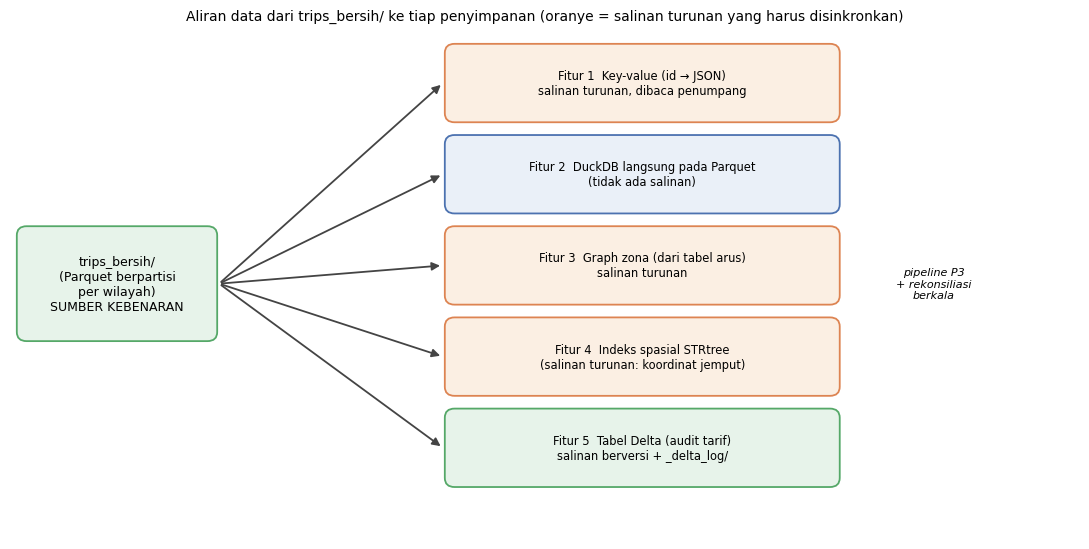

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 5.6)); ax.set_xlim(0, 110); ax.set_ylim(0, 56); ax.axis("off")
def kotak_(x, y, w, h, teks, warna="#EAF0F8", tepi="#4C72B0", fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1", fc=warna, ec=tepi, lw=1.3))
    ax.text(x + w/2, y + h/2, teks, ha="center", va="center", fontsize=fs)
def panah(x1, y1, x2, y2, label=None):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, lw=1.3, color="#444"))
    if label: ax.text((x1+x2)/2, (y1+y2)/2 + 1.2, label, fontsize=7.5, ha="center", color="#444")

kotak_(1, 22, 20, 12, "trips_bersih/\n(Parquet berpartisi\nper wilayah)\nSUMBER KEBENARAN", "#E7F3EA", "#55A868", 9)
tujuan = [
  (46, "Fitur 1  Key-value (id → JSON)\nsalinan turunan, dibaca penumpang", "#FBEFE3", "#DD8452"),
  (36, "Fitur 2  DuckDB langsung pada Parquet\n(tidak ada salinan)", "#EAF0F8", "#4C72B0"),
  (26, "Fitur 3  Graph zona (dari tabel arus)\nsalinan turunan", "#FBEFE3", "#DD8452"),
  (16, "Fitur 4  Indeks spasial STRtree\n(salinan turunan: koordinat jemput)", "#FBEFE3", "#DD8452"),
  (6,  "Fitur 5  Tabel Delta (audit tarif)\nsalinan berversi + _delta_log/", "#E7F3EA", "#55A868"),
]
for y, t, w, e in tujuan:
    kotak_(45, y, 40, 8, t, w, e, 8.3); panah(21.5, 28, 44.5, y + 4)
ax.text(95, 28, "pipeline P3\n+ rekonsiliasi\nberkala", ha="center", va="center", fontsize=8, style="italic")
ax.set_title("Aliran data dari trips_bersih/ ke tiap penyimpanan (oranye = salinan turunan yang harus disinkronkan)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{DIR_SIMPAN}/diagram_aliran_data.png", dpi=150); plt.show()

**Paragraf data ganda.** Bagian rancangan yang terpaksa menyimpan data ganda adalah fitur 1 (salinan key-value per perjalanan), fitur 3 (graph yang diturunkan dari tabel arus), fitur 4 (indeks spasial atas titik jemput) dan fitur 5 (tabel Delta yang berisi tarif yang sama dengan sumbernya). Sumber kebenaran tunggalnya adalah `trips_bersih/` (Parquet). Kedua salinan dijaga tetap sama dengan tiga cara: (1) **satu arah** — salinan tidak pernah ditulis langsung oleh aplikasi, hanya dibangun ulang/diperbarui oleh pipeline dari sumber kebenaran, dengan kunci deterministik (id perjalanan) sehingga menjalankan ulang tidak menggandakan data (idempoten, Praktikum 3); (2) **rekonsiliasi berkala** — membandingkan jumlah baris dan jumlah `total_bayar` antara salinan dan sumbernya (dicontohkan pada sel di bawah); dan (3) **perubahan tarif hanya lewat Delta** sehingga setiap koreksi tercatat sebagai versi di `_delta_log/` dan bisa diulang ke salinan lain dengan membaca versi yang sama.

In [ ]:
# Contoh rekonsiliasi: salinan key-value (kv) vs sumber kebenaran (df = isi trips_bersih/), pada 300.000 perjalanan contoh
def rekonsiliasi(kv_salinan, sumber):
    w_sumber = sumber.groupby("wilayah_jemput")["total_bayar"].agg(["count", "sum"]).round(2)
    w_kv = {}
    for teks in kv_salinan.values():
        d = json.loads(teks); a = w_kv.setdefault(d["wilayah_jemput"], [0, 0.0]); a[0] += 1; a[1] += d["total_bayar"]
    w_kv = pd.DataFrame(w_kv, index=["count", "sum"]).T.round(2)
    gabung = w_sumber.join(w_kv, lsuffix="_sumber", rsuffix="_kv")
    gabung["cocok?"] = (gabung["count_sumber"] == gabung["count_kv"]) & ((gabung["sum_sumber"] - gabung["sum_kv"]).abs() < 0.05)
    return gabung

print("Rekonsiliasi kv vs sumber (sampel yang sama, harus cocok semua):")
print(rekonsiliasi(kv, sample).to_string())
kv_rusak = dict(kv); kunci0 = next(iter(kv_rusak)); d0 = json.loads(kv_rusak[kunci0]); d0["total_bayar"] += 100; kv_rusak[kunci0] = json.dumps(d0)
print("\nBila satu nilai salinan berubah diam-diam (+100 pada satu perjalanan), rekonsiliasi menangkapnya:")
r_ = rekonsiliasi(kv_rusak, sample); print(r_[~r_["cocok?"]].to_string())

Rekonsiliasi kv vs sumber (sampel yang sama, harus cocok semua):
                            count_sumber  sum_sumber  count_kv      sum_kv  cocok?
wilayah_jemput                                                                    
Bronx                                291    10757.97     291.0    10757.97    True
Brooklyn                            1499    48864.11    1499.0    48864.11    True
EWR                                    4      434.46       4.0      434.46    True
Manhattan                         267074  6062075.10  267074.0  6062075.10    True
Queens                             27288  1921475.64   27288.0  1921475.64    True
Staten Island                         29     2083.69      29.0     2083.69    True
Unknown                             3778   147689.56    3778.0   147689.56    True
__HIVE_DEFAULT_PARTITION__            37     2546.71      37.0     2546.71    True

Bila satu nilai salinan berubah diam-diam (+100 pada satu perjalanan), rekonsiliasi menangkapnya:
      

**Interpretasi paragraf data ganda.** Rekonsiliasi membandingkan jumlah baris dan jumlah `total_bayar` per wilayah antara salinan key-value dan sumber kebenaran: kedelapan kelompok wilayah **cocok** (mis. Manhattan 267.074 baris, 6.062.075,10). Ketika satu nilai salinan sengaja diubah +100 pada satu perjalanan, rekonsiliasi langsung menangkapnya: hanya **Manhattan** yang ditandai tidak cocok (6.062.075,1 pada sumber vs 6.062.175,1 pada salinan), dengan selisih tepat 100. Ini menunjukkan bahwa menjaga dua salinan tetap sama adalah **pekerjaan yang harus dirancang** (pipeline satu arah + pemeriksaan berkala), bukan sesuatu yang terjadi otomatis.

## Q. Latihan

Dikerjakan di jam praktikum, pada notebook yang sama.

### Latihan 1
Ulangi pencarian K-2 dengan 2.000 id acak untuk tabel berindeks dan key-value saja. Hitung waktu rata-rata per pencarian dalam mikrodetik untuk masing-masing.

In [ ]:
random.seed(7)
id_uji2 = random.sample(range(1, len(data) + 1), 2000)
def cari_sql_2000():
    cur = con.cursor()
    return [cur.execute("SELECT * FROM perjalanan WHERE id_perjalanan = ?", (i,)).fetchone() for i in id_uji2]
def cari_kv_2000():
    return [json.loads(kv[f"perjalanan:{i}"]) for i in id_uji2]

def ulang_waktu(f, n=7):
    w = []
    for _ in range(n):
        t0 = time.perf_counter(); f(); w.append(time.perf_counter() - t0)
    return w
w_sql = ulang_waktu(cari_sql_2000); w_kv = ulang_waktu(cari_kv_2000)
for nama, w in (("tabel berindeks", w_sql), ("key-value", w_kv)):
    print(f"{nama:16s}: median total {np.median(w):.5f} s -> rata-rata per pencarian {np.median(w)/2000*1e6:.2f} µs "
          f"(min {min(w)/2000*1e6:.2f} µs, maks {max(w)/2000*1e6:.2f} µs, 7 ulangan)")
print(f"rasio tabel berindeks / key-value = {np.median(w_sql)/np.median(w_kv):.2f} x")

tabel berindeks : median total 0.03975 s -> rata-rata per pencarian 19.88 µs (min 15.69 µs, maks 26.40 µs, 7 ulangan)
key-value       : median total 0.00999 s -> rata-rata per pencarian 5.00 µs (min 4.88 µs, maks 5.51 µs, 7 ulangan)
rasio tabel berindeks / key-value = 3.98 x


**Interpretasi Latihan 1.** Dengan 2.000 id acak (median 7 ulangan), tabel berindeks rata-rata **19,88 µs** per pencarian (rentang 15,69–26,40 µs) dan key-value **5,00 µs** (rentang 4,88–5,51 µs), sehingga tabel berindeks **±3,98 kali** lebih lambat. Angka ini berbeda dari K-2 (17,5 µs dan 6,0 µs; rasio ±2,9 kali) kemungkinan karena jumlah pencarian lebih banyak, hasilnya dirata-ratakan dari 7 ulangan, dan waktu K-2 hanya satu kali ukur dengan pembulatan empat desimal. Kesimpulannya sama: keduanya berada di orde mikrodetik, jauh dari 62,93 ms tanpa indeks.

### Latihan 2
Pada K-3, hitung dokumen dengan zona tujuan tertentu dan `metode_bayar` "Tunai". Hitung juga angka yang sama lewat SQL pada tabel di K-2. Apakah sama? Bila tidak, apa sebabnya?

In [ ]:
from collections import Counter
# zona tujuan tertentu: zona yang paling sering menjadi tujuan perjalanan Tunai di dokumen K-3
ZT = Counter(d["tujuan"]["zona"] for d in tabel.all() if d["biaya"]["metode_bayar"] == "Tunai").most_common(1)[0][0]
n_doc = len(tabel.search((Q.tujuan.zona == ZT) & (Q.biaya.metode_bayar == "Tunai")))
n_sql = con.execute("SELECT COUNT(*) FROM perjalanan WHERE zona_tujuan = ? AND metode_bayar = 'Tunai'", (ZT,)).fetchone()[0]
n_sql_20k = con.execute("SELECT COUNT(*) FROM perjalanan WHERE zona_tujuan = ? AND metode_bayar = 'Tunai' AND id_perjalanan <= 20000", (ZT,)).fetchone()[0]
print(f"zona tujuan yang dipilih: {ZT}")
print(f"TinyDB (K-3, {len(tabel):,} dokumen)           : {n_doc}")
print(f"SQL seluruh tabel K-2 ({len(data):,} baris)   : {n_sql}")
print(f"SQL pada 20.000 baris pertama (id <= 20000): {n_sql_20k}")
print("sama (seluruh tabel)?", n_doc == n_sql, "| sama (cakupan data disamakan)?", n_doc == n_sql_20k)
print("dokumen ke-20.001 (id 999999, Kartu kredit) tidak ikut terhitung karena metode_bayar-nya bukan Tunai.")

zona tujuan yang dipilih: 237
TinyDB (K-3, 20,001 dokumen)           : 152
SQL seluruh tabel K-2 (300,000 baris)   : 2116
SQL pada 20.000 baris pertama (id <= 20000): 152
sama (seluruh tabel)? False | sama (cakupan data disamakan)? True
dokumen ke-20.001 (id 999999, Kartu kredit) tidak ikut terhitung karena metode_bayar-nya bukan Tunai.


**Interpretasi Latihan 2.** Untuk zona tujuan **237** dan pembayaran Tunai, TinyDB menemukan **152** dokumen, sedangkan SQL pada seluruh tabel K-2 menemukan **2.116** baris, jadi hasilnya **tidak sama**. Sebabnya adalah **cakupan data**: dokumen K-3 hanya dibuat dari 20.000 baris pertama contoh (ditambah satu dokumen id 999.999 berpembayaran Kartu kredit, yang tidak ikut terhitung), sedangkan tabel K-2 berisi 300.000 baris. Setelah cakupan disamakan (`id_perjalanan <= 20000`), SQL menghasilkan **152**, **sama persis** dengan TinyDB. Catatan: 152 lebih besar daripada porsi proporsional (2.116 × 20.000/300.000 ≈ 141) karena zona 237 dipilih sebagai zona Tunai teratas pada dokumen K-3 itu sendiri.

### Latihan 3
Pada K-4, jalankan `SUM` atas satu kolom angka, lalu `SUM` atas beberapa kolom angka sekaligus. Bandingkan waktunya dan jelaskan dengan *column pruning* (Praktikum 3/K-4).

In [ ]:
def med_duck(sql, n=9):
    w = []
    for _ in range(n):
        t0 = time.perf_counter(); con_d.sql(sql).fetchall(); w.append(time.perf_counter() - t0)
    return float(np.median(w))

q_satu = "SELECT SUM(total_bayar) FROM perjalanan"
q_banyak = "SELECT SUM(total_bayar), SUM(jarak_mil), SUM(zona_jemput), SUM(zona_tujuan) FROM perjalanan"
_ = con_d.sql(q_banyak).fetchall()                      # pemanasan agar file sudah di cache OS
t_satu = med_duck(q_satu); t_banyak = med_duck(q_banyak)
print(f"SUM 1 kolom (total_bayar)            : {t_satu*1e3:.2f} ms (median 9 kali)")
print(f"SUM 4 kolom (total_bayar, jarak_mil, zona_jemput, zona_tujuan): {t_banyak*1e3:.2f} ms")
print(f"4 kolom / 1 kolom = {t_banyak/t_satu:.2f} x | kolom yang dibaca: 1 dari 7 di view (1 dari {df.shape[1]} kolom file) vs 4 dari 7")

SUM 1 kolom (total_bayar)            : 183.27 ms (median 9 kali)
SUM 4 kolom (total_bayar, jarak_mil, zona_jemput, zona_tujuan): 322.79 ms
4 kolom / 1 kolom = 1.76 x | kolom yang dibaca: 1 dari 7 di view (1 dari 18 kolom file) vs 4 dari 7


**Interpretasi Latihan 3.** `SUM` satu kolom (`total_bayar`) memakan **183,27 ms**, sedangkan `SUM` empat kolom angka sekaligus **322,79 ms**: **±1,76 kali** lebih lama. Ini sejalan dengan *column pruning* (Praktikum 3/K-4): pada Parquet tiap kolom disimpan terpisah dan hanya kolom yang disebut query yang dibaca, sehingga biaya naik seiring jumlah kolom yang dibaca (1 → 4 kolom dari 18 kolom file). Kenaikannya jauh lebih kecil daripada 4 kali karena ada biaya tetap (membuka file, membaca footer, menjalankan query) yang sama untuk keduanya.

### Latihan 4
Pada K-5, cari lima zona dengan jumlah zona tujuan berbeda terbanyak menggunakan graph (*out-degree*), lalu silangkan dengan SQL memakai `COUNT(DISTINCT tujuan)`.

In [ ]:
top_out_graph = sorted(G.out_degree(), key=lambda kv_: (-kv_[1], kv_[0]))[:5]            # out-degree = jumlah zona tujuan berbeda
top_out_sql = con_d.sql("""SELECT asal, COUNT(DISTINCT tujuan) AS n FROM arus GROUP BY asal
                           ORDER BY n DESC, asal LIMIT 5""").df()
print("graph (out-degree):", top_out_graph)
print("SQL (COUNT DISTINCT):", list(top_out_sql.itertuples(index=False, name=None)))
print("sama?", [(int(a), int(b)) for a, b in top_out_graph] == [(int(a), int(b)) for a, b in top_out_sql.itertuples(index=False, name=None)])
print("jumlah maksimum tujuan yang mungkin (263 zona, tanpa diri sendiri = 262, dengan diri sendiri = 263)")

graph (out-degree): [(132, 260), (138, 254), (264, 241), (230, 234), (140, 233)]
SQL (COUNT DISTINCT): [(132, 260), (138, 254), (264, 241), (230, 234), (140, 233)]
sama? True
jumlah maksimum tujuan yang mungkin (263 zona, tanpa diri sendiri = 262, dengan diri sendiri = 263)


**Interpretasi Latihan 4.** Graph (`out_degree`) dan SQL (`COUNT(DISTINCT tujuan)`) memberi lima zona yang **sama persis**: **132 (260 zona tujuan berbeda), 138 (254), 264 (241), 230 (234), dan 140 (233)**. Angkanya berbeda-beda dan tidak ada yang mencapai seluruh 262 zona pada graph, sehingga urutannya ditentukan oleh jumlah tujuan, bukan oleh pengurut tambahan (M.5), yang hanya berfungsi bila ada seri. Zona dengan tujuan paling beragam adalah zona yang menjadi simpul perjalanan ke banyak tempat (menurut tabel zona TLC, 132 dan 138 adalah bandara JFK dan LaGuardia; ini keterangan di luar notebook).

### Latihan 5
Pada K-6, ulangi pengukuran dengan sisi kotak 0,02 derajat dan 0,001 derajat. Bagaimana perbandingan STRtree terhadap NumPy berubah? Mengapa kotak yang lebih kecil lebih menguntungkan indeks?

In [ ]:
def uji_sisi(sisi, ulang=3):
    h = sisi / 2
    kotak_s = [box(x - h, y - h, x + h, y + h) for x, y in zip(cx, cy)]
    def np_():
        return [int(((bujur >= x - h) & (bujur <= x + h) & (lintang >= y - h) & (lintang <= y + h)).sum()) for x, y in zip(cx, cy)]
    def idx_():
        return [len(pohon.query(k, predicate="contains")) for k in kotak_s]
    wn = []; wi = []
    for _ in range(ulang):
        t0 = time.perf_counter(); hn = np_(); wn.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); hi = idx_(); wi.append(time.perf_counter() - t0)
    return {"sisi (derajat)": sisi, "NumPy (s)": round(float(np.median(wn)), 4), "STRtree cari (s)": round(float(np.median(wi)), 4),
            "NumPy / STRtree": round(float(np.median(wn)) / float(np.median(wi)), 2),
            "rata-rata titik/kotak": round(sum(hi) / len(hi), 1), "hasil sama?": hn == hi}
hasil_sisi = pd.DataFrame([uji_sisi(s) for s in (0.02, 0.01, 0.001)])
print(hasil_sisi.to_string(index=False))
print(f"\n(indeks STRtree dibangun sekali: {T['bangun indeks STRtree']:.4f} s; 0,01 derajat = ukuran K-6)")

 sisi (derajat)  NumPy (s)  STRtree cari (s)  NumPy / STRtree  rata-rata titik/kotak  hasil sama?
          0.020     0.4903            1.0780             0.45                 1666.6         True
          0.010     0.6349            0.3055             2.08                  417.5         True
          0.001     0.4935            0.0118            41.74                    4.1         True

(indeks STRtree dibangun sekali: 0.0688 s; 0,01 derajat = ukuran K-6)


**Interpretasi Latihan 5.** Hasil NumPy dan STRtree sama pada semua ukuran (`True`). Perbandingannya berubah drastis menurut ukuran kotak:

| Sisi kotak | NumPy | STRtree (cari) | NumPy / STRtree | Rata-rata titik/kotak |
|---|---|---|---|---|
| 0,020° | 0,4903 s | 1,0780 s | **0,45** (STRtree justru ±2,2 kali lebih lambat) | 1.666,6 |
| 0,010° | 0,6349 s | 0,3055 s | **2,08** | 417,5 |
| 0,001° | 0,4935 s | 0,0118 s | **41,74** | 4,1 |

NumPy hampir tidak berubah (±0,49–0,63 s) karena **selalu memeriksa semua 200.000 titik** untuk setiap kotak, berapa pun ukurannya. STRtree hanya menelusuri bagian pohon yang bersinggungan dengan kotak, sehingga biayanya naik-turun menurut banyaknya titik yang ditemukan: kotak lebih kecil → lebih banyak cabang dilewati → jauh lebih cepat. Pada kotak besar (1.667 titik per kotak) keuntungan itu habis, bahkan terbalik. Indeks paling menguntungkan bila wilayah pencarian **kecil** (seperti “radius 500 meter”) dan titiknya banyak. Catatan: pada ukuran 0,01° (sama dengan K-6) NumPy 0,6349 s dan STRtree 0,3055 s, sedikit berbeda dari K-6 (0,5375 s dan 0,2304 s; rasio 2,33) karena pengukuran berulang dan derau waktu pada mesin ini.

### Latihan 6
Jalankan sel di bawah setelah K-8. Jelaskan perbedaan *time travel* (membaca versi lama) dengan *restore* (mengembalikan tabel ke versi lama), dan mengapa restore dicatat sebagai versi baru, bukan menghapus riwayat.

In [ ]:
dt = DeltaTable(PATH_DELTA)
print("versi sebelum restore:", dt.version(), "| baris:", len(dt.to_pandas()))
dt.restore(1)     # kembalikan tabel ke keadaan versi 1 (dicatat sebagai versi baru)
dt = DeltaTable(PATH_DELTA)
print("versi setelah restore:", dt.version(), "| baris:", len(dt.to_pandas()))
print([h.get("operation") for h in dt.history()][:3])

versi sebelum restore: 23 | baris: 160000
versi setelah restore: 24 | baris: 150000
['RESTORE', 'OPTIMIZE', 'WRITE']


In [ ]:
# Pendukung Latihan 6: restore tidak menghapus riwayat - versi lama (mis. versi 22 sebelum compaction & versi 23) tetap bisa dibaca
print("riwayat (terbaru dulu):", [(h.get("version"), h.get("operation")) for h in DeltaTable(PATH_DELTA).history()][:5])
print("baris versi 22 (sebelum compaction):", len(DeltaTable(PATH_DELTA, version=22).to_pandas()),
      "| versi 23 (hasil compaction):", len(DeltaTable(PATH_DELTA, version=23).to_pandas()),
      "| versi 24 (hasil restore ke v1):", len(DeltaTable(PATH_DELTA, version=24).to_pandas()))
print("berkas di _delta_log:", len([f for f in os.listdir(f"{PATH_DELTA}/_delta_log") if f.endswith('.json')]))

riwayat (terbaru dulu): [(24, 'RESTORE'), (23, 'OPTIMIZE'), (22, 'WRITE'), (21, 'WRITE'), (20, 'WRITE')]
baris versi 22 (sebelum compaction): 160000 | versi 23 (hasil compaction): 160000 | versi 24 (hasil restore ke v1): 150000
berkas di _delta_log: 25


**Interpretasi Latihan 6.** Sebelum restore tabel berada di versi **23** (160.000 baris); `restore(1)` menghasilkan versi **24** dengan **150.000 baris**, dan riwayat teratas menjadi `['RESTORE', 'OPTIMIZE', 'WRITE']`. **Time travel** (`DeltaTable(path, version=n)`) hanya *membaca* keadaan lama dan tidak mengubah tabel; **restore** *mengubah* tabel sehingga keadaan terkini kembali seperti versi 1. Restore dicatat sebagai **versi baru** (versi 24), bukan menghapus riwayat, karena log transaksi hanya bertambah (*append-only*): versi 22 (160.000 baris), 23 (160.000 baris), dan 24 (150.000 baris) tetap bisa dibaca dan berkas log menjadi 25. Dengan begitu restore itu sendiri bisa diaudit dan dibatalkan, dan riwayat tidak hilang. Catatan: setelah sel ini tabel `trips_delta` berada di versi 24; arsip `trips_delta.zip` pada Tugas 4 dibuat dari keadaan ini.

## R. Tugas Praktikum

Batas waktu: 7 hari setelah praktikum, melalui iLearn dan dikerjakan mandiri.

1. **Rekap benchmark.** Kumpulkan `benchmark_nosql.csv` dan tabel rekap K-9 yang sudah terisi, dengan satu kalimat interpretasi untuk tiap baris.
2. **Data lain, cara lain.** Pilih satu data lain (mis. “zona”, “hari”, atau “metode bayar”) dan rancang tiga cara menyimpannya (tabel, document, dan graph atau key-value). Untuk masing-masing, tulis satu pertanyaan yang mudah dan satu yang canggung dijawab.
3. **Delta Lake dua hari.** Simulasikan dua hari kerja: hari pertama menulis sebagian data, hari kedua menambah data dan mengoreksi beberapa baris. Tunjukkan bahwa Anda bisa membaca tabel seperti keadaannya di akhir hari pertama, dan lampirkan isi `_delta_log/`.
4. Laporan rancangan penyimpanan untuk studi kasus di Bagian P (PDF), dan *Restart notebook and run all* pada runtime bersih.

Berkas yang dikumpulkan: file notebook `.ipynb` (dengan output), `benchmark_nosql.csv`, arsip `trips_delta.zip`, dan laporan PDF.

### Tugas 1 — Rekap benchmark
Tabel rekap K-9 berikut memuat satu kalimat interpretasi per baris. Kalimat dibentuk **otomatis dari angka hasil running** (bukan diketik), lalu disimpan sebagai `tabel_rekap_k9.csv` di samping `benchmark_nosql.csv`.

In [ ]:
kv_c = T["hitung per wilayah - key-value (buka semua nilai)"]; sq_c = T["hitung per wilayah - SQL GROUP BY"]
dd = T["DuckDB - hitung per wilayah (langsung dari Parquet)"]; sl = T["SQLite - hitung per wilayah"]
g2 = T["2 langkah - graph (NetworkX)"]; s2 = T["2 langkah - SQL self-join (DuckDB)"]
tb = T["bangun indeks STRtree"]; tc = T["cara 3 - STRtree, 1000 kotak"]; tn = T["cara 2 - NumPy, 1000 kotak"]; tl5 = T["cara 1 - loop Python, 5 kotak"]
ta = T["cari 200 perjalanan - SQL tanpa indeks"]; tb_ = T["cari 200 perjalanan - SQL dengan indeks"]; tk = T["cari 200 perjalanan - key-value"]
interpretasi = [
  f"Tabel tanpa indeks {ta/tb_:,.0f}x lebih lambat daripada tabel berindeks ({ta:.4f} s vs {tb_:.4f} s untuk 200 pencarian), sedangkan key-value hanya {tb_/tk:.1f}x lebih cepat dari tabel berindeks ({tk:.4f} s): untuk satu mesin, indeks sudah menutup hampir seluruh kesenjangan.",
  f"DuckDB pada Parquet ({dd:.4f} s) {sl/dd:.1f}x lebih cepat daripada SQLite ({sl:.4f} s), sementara key-value {kv_c/sq_c:.1f}x lebih lambat daripada SQL GROUP BY ({kv_c:.4f} s vs {sq_c:.4f} s) karena setiap nilai harus dibuka dulu.",
  f"Dokumen ke-20.001 membawa field baru 'cuaca' tanpa ALTER TABLE dan {len(tabel.search(~Q.biaya.tip.exists())):,} dokumen tidak punya field 'tip' (pada tabel menjadi NULL/migrasi), tetapi database juga tidak menegur field yang salah ketik.",
  f"Graph dan SQL sama-sama menemukan {len(hg)} zona dalam 2 langkah ({g2:.4f} s vs {s2:.4f} s pada run ini), jadi keunggulan graph ada pada kemudahan menaikkan k (satu angka) dibanding satu JOIN tambahan per langkah di SQL.",
  f"STRtree ({tc:.4f} s untuk 1.000 kotak) {tn/tc:.1f}x lebih cepat daripada NumPy ({tn:.4f} s) tetapi jauh lebih cepat daripada loop Python (perkiraan {tl5/5*1000:.0f} s): besar keuntungan bergantung pada pembandingnya.",
  f"Tabel Delta menyimpan {len(DeltaTable(PATH_DELTA).history())} versi; update {n_koreksi:,} baris dapat ditelusuri lewat selisih total_bayar {selisih:.1f} dan kolom asing ditolak tanpa mengubah versi, sesuatu yang tidak dimiliki folder Parquet biasa.",
]
tabel_rekap_final = tabel_rekap.copy(); tabel_rekap_final["Interpretasi"] = interpretasi
tabel_rekap_final.to_csv(f"{DIR_SIMPAN}/tabel_rekap_k9.csv", index=False)
for _, r in tabel_rekap_final.iterrows():
    print(f"\n[{r['Kebutuhan']}]\n  unggul: {r['Cara yang unggul']} | lemah: {r['Cara yang lemah']}\n  angka : {r['Angka Anda']}\n  -> {r['Interpretasi']}")
print("\nberkas tersimpan:", sorted(f for f in os.listdir(DIR_SIMPAN) if f.endswith('.csv')))


[Ambil satu data lewat id]
  unggul: Key-value; tabel dengan indeks | lemah: Tabel tanpa indeks
  angka : tanpa indeks 12.5850 s | dengan indeks 0.0035 s | key-value 0.0012 s (200 pencarian)
  -> Tabel tanpa indeks 3,596x lebih lambat daripada tabel berindeks (12.5850 s vs 0.0035 s untuk 200 pencarian), sedangkan key-value hanya 2.9x lebih cepat dari tabel berindeks (0.0012 s): untuk satu mesin, indeks sudah menutup hampir seluruh kesenjangan.

[Menghitung atau merangkum banyak baris]
  unggul: Per kolom (DuckDB pada Parquet) | lemah: Key-value (buka semua nilai)
  angka : DuckDB 0.3159 s | SQLite 1.7888 s | key-value 1.9684 s vs SQL 0.1974 s
  -> DuckDB pada Parquet (0.3159 s) 5.7x lebih cepat daripada SQLite (1.7888 s), sementara key-value 10.0x lebih lambat daripada SQL GROUP BY (1.9684 s vs 0.1974 s) karena setiap nilai harus dibuka dulu.

[Data dengan field opsional atau berubah-ubah]
  unggul: Document | lemah: Tabel (kolom NULL, migrasi)
  angka : (kualitatif)
  -> Dokumen ke-2

**Interpretasi Tugas 1.** Enam kalimat interpretasi di atas dibentuk dari angka run ini (data asli) dan disimpan bersama tabel rekap sebagai `tabel_rekap_k9.csv` (di samping `benchmark_nosql.csv`). Intinya: arah hasil mengikuti modul untuk semua baris — indeks menutup hampir seluruh kesenjangan pencarian (±3.596 kali), penyimpanan per kolom unggul untuk menghitung (±5,7 kali), graph dan SQL sama cepat pada 2 langkah (0,0079 s vs 0,0059 s), keuntungan STRtree bergantung pada pembanding (±2,3 kali terhadap NumPy), dan hanya Delta yang punya versi, penolakan skema, dan restore. Besaran pastinya berbeda dari contoh modul karena data dan mesin saya berbeda.

### Tugas 2 — Data lain, cara lain
**Data yang dipilih: “zona”** (263 zona jemput). Tiga cara menyimpannya: **tabel** (SQLite), **document** (TinyDB: satu dokumen per zona berisi profil dan lima tujuan teratas), dan **graph** (graph arus antar zona dari K-5). Untuk tiap cara ditulis satu pertanyaan yang mudah dan satu yang canggung, lalu keduanya dijalankan.

In [ ]:
# --- Bahan: ringkasan per zona dari data K-1 (seluruh isi trips_bersih/) ---
zona_info = (df.groupby("zona_jemput").agg(wilayah=("wilayah_jemput", lambda s: s.mode().iat[0]), jumlah_jemput=("zona_jemput", "size")).reset_index())
top5 = (arus.sort_values(["asal", "jumlah", "tujuan"], ascending=[True, False, True]).groupby("asal").head(5))

# --- Cara 1: TABEL (SQLite) ---
if os.path.exists("zona.db"): os.remove("zona.db")
con_z = sqlite3.connect("zona.db")
zona_info.rename(columns={"zona_jemput": "zona_id"}).to_sql("zona", con_z, index=False)
arus.to_sql("arus", con_z, index=False)
con_z.execute("CREATE INDEX idx_arus_asal ON arus(asal)")

# --- Cara 2: DOCUMENT (TinyDB): satu dokumen per zona, tujuan teratas disematkan (embedding) ---
dbz = TinyDB(storage=MemoryStorage); tz = dbz.table("zona")
tujuan_per_zona = {}
for r in top5.itertuples():
    tujuan_per_zona.setdefault(int(r.asal), []).append({"zona": int(r.tujuan), "jumlah": int(r.jumlah)})
tz.insert_multiple([{"zona_id": int(r.zona_jemput), "wilayah": r.wilayah, "jumlah_jemput": int(r.jumlah_jemput),
                     "tujuan_teratas": tujuan_per_zona.get(int(r.zona_jemput), [])} for r in zona_info.itertuples()])

# --- Cara 3: GRAPH: G dari K-5; tambahkan atribut node (wilayah, jumlah_jemput) ---
for r in zona_info.itertuples():
    if G.has_node(int(r.zona_jemput)):
        G.nodes[int(r.zona_jemput)]["wilayah"] = r.wilayah; G.nodes[int(r.zona_jemput)]["jumlah_jemput"] = int(r.jumlah_jemput)
print("tabel zona:", con_z.execute("SELECT COUNT(*) FROM zona").fetchone()[0], "baris | dokumen zona:", len(tz), "| node graph:", G.number_of_nodes())

def waktu(f, n=20):
    w = []
    for _ in range(n):
        t0 = time.perf_counter(); hsl = f(); w.append(time.perf_counter() - t0)
    return hsl, float(np.median(w))
Z = int(populer[0][0])

print("\n=== TABEL ===")
h_t1, w_t1 = waktu(lambda: con_z.execute("SELECT wilayah, COUNT(*), SUM(jumlah_jemput), ROUND(AVG(jumlah_jemput),1) FROM zona GROUP BY wilayah ORDER BY 3 DESC").fetchall())
print(f"MUDAH   : total dan rata-rata jemput per wilayah (GROUP BY) -> {w_t1*1e3:.3f} ms\n  {h_t1[:3]}")
h_t2, w_t2 = waktu(lambda: con_z.execute(f"""SELECT COUNT(DISTINCT c.tujuan) FROM arus a JOIN arus b ON a.tujuan=b.asal JOIN arus c ON b.tujuan=c.asal
     WHERE a.asal={Z} AND a.jumlah>={MIN} AND b.jumlah>={MIN} AND c.jumlah>={MIN} AND c.tujuan<>{Z}""").fetchone()[0], n=5)
print(f"CANGGUNG: zona yang bisa dicapai TEPAT 3 langkah dari zona {Z} (2 self-join, SQL makin panjang) -> {h_t2} zona, {w_t2*1e3:.1f} ms")

print("\n=== DOCUMENT ===")
h_d1, w_d1 = waktu(lambda: tz.get(Query().zona_id == Z))
print(f"MUDAH   : ambil profil lengkap zona {Z} beserta 5 tujuan teratas dalam SATU dokumen -> {w_d1*1e3:.3f} ms\n  {h_d1}")
def zona_populer_sebagai_tujuan_teratas():
    hit = Counter()
    for d in tz.all():
        if d["tujuan_teratas"]: hit[d["tujuan_teratas"][0]["zona"]] += 1
    return hit.most_common(3)
h_d2, w_d2 = waktu(zona_populer_sebagai_tujuan_teratas, n=5)
print(f"CANGGUNG: zona mana yang paling sering menjadi tujuan nomor 1 dari zona lain (hubungan ANTAR dokumen; harus memindai semua dokumen) -> {w_d2*1e3:.1f} ms\n  {h_d2}")

print("\n=== GRAPH ===")
h_g1, w_g1 = waktu(lambda: len(nx.single_source_shortest_path_length(H, Z, cutoff=3)) - 1)
print(f"MUDAH   : zona yang terjangkau dalam <= 3 langkah dari zona {Z} (ganti satu angka k) -> {h_g1} zona, {w_g1*1e3:.3f} ms")
def agregasi_per_wilayah_graph():
    tot = Counter()
    for n_, a in G.nodes(data=True): tot[a.get("wilayah", "?")] += a.get("jumlah_jemput", 0)
    return tot.most_common(3)
h_g2, w_g2 = waktu(agregasi_per_wilayah_graph, n=20)
print(f"CANGGUNG: total jemput per wilayah (agregasi tabel; harus menelusuri node satu per satu, tanpa GROUP BY) -> {w_g2*1e3:.3f} ms\n  {h_g2}")

tabel zona: 254 baris | dokumen zona: 254 | node graph: 262

=== TABEL ===
MUDAH   : total dan rata-rata jemput per wilayah (GROUP BY) -> 0.130 ms
  [('Manhattan', 66, 2659609, 40297.1), ('Queens', 68, 270315, 3975.2), ('Unknown', 1, 37609, 37609.0)]
CANGGUNG: zona yang bisa dicapai TEPAT 3 langkah dari zona 236 (2 self-join, SQL makin panjang) -> 214 zona, 263.0 ms

=== DOCUMENT ===
MUDAH   : ambil profil lengkap zona 236 beserta 5 tujuan teratas dalam SATU dokumen -> 0.094 ms
  {'zona_id': 236, 'wilayah': 'Manhattan', 'jumlah_jemput': 136276, 'tujuan_teratas': [{'zona': 237, 'jumlah': 18810}, {'zona': 236, 'jumlah': 14110}, {'zona': 161, 'jumlah': 7497}, {'zona': 239, 'jumlah': 6877}, {'zona': 141, 'jumlah': 6876}]}
CANGGUNG: zona mana yang paling sering menjadi tujuan nomor 1 dari zona lain (hubungan ANTAR dokumen; harus memindai semua dokumen) -> 0.3 ms
  [(230, 10), (79, 9), (231, 8)]

=== GRAPH ===
MUDAH   : zona yang terjangkau dalam <= 3 langkah dari zona 236 (ganti satu angka 

**Interpretasi Tugas 2 (data “zona”).** Tabel zona berisi 254 baris (zona yang pernah menjadi lokasi jemput), dokumen zona 254, dan graph 262 node (delapan zona di antaranya hanya muncul sebagai tujuan).

| Cara | Pertanyaan **mudah** | Pertanyaan **canggung** |
|---|---|---|
| **Tabel** (SQLite) | Total/rata-rata jemput per wilayah: satu `GROUP BY`, **0,130 ms** (Manhattan 66 zona, 2.659.609 jemputan) | Zona yang dicapai tepat 3 langkah dari zona 236: butuh 2 self-join dan **263,0 ms** (214 zona); makin banyak langkah, makin panjang SQL-nya |
| **Document** (TinyDB) | Profil lengkap zona 236 (136.276 jemputan) + 5 tujuan teratas dalam **satu dokumen**: **0,094 ms** (embedding) | Zona yang paling sering menjadi tujuan nomor 1 dari zona lain: hubungan **antar dokumen** harus memindai semua dokumen (0,3 ms; hasil: zona 230 sebanyak 10 kali, zona 79 sebanyak 9 kali, zona 231 sebanyak 8 kali) |
| **Graph** (NetworkX) | Zona terjangkau dalam ≤ 3 langkah: ganti satu angka k, **0,089 ms** (214 zona) | Total jemput per wilayah: agregasi tabel tanpa `GROUP BY`; harus menelusuri node satu per satu (0,089 ms, hasil sama dengan tabel: Manhattan 2.659.609, Queens 270.315, Unknown 37.609) |

Catatan kehati-hatian: perbandingan waktu di sini kasar. Pada graph/dokumen datanya sudah berada di memori dan sudah disiapkan, sedangkan 263,0 ms pada SQL mencakup join atas 21.583 arus untuk langkah *tepat 3* (bukan ≤ 3), dan pertanyaan “canggung” pada dokumen/graph tetap cepat karena hanya 254–262 elemen. Yang dibuktikan adalah **bentuk** pertanyaan: pertanyaan “canggung” bukan selalu lambat, melainkan paling tidak alami ditulis pada model tersebut.

### Tugas 3 — Delta Lake dua hari
Simulasi dua hari kerja pada tabel Delta baru (`trips_delta_2hari`): **hari pertama** menulis sebagian data; **hari kedua** menambah data dan mengoreksi beberapa baris. Lalu tabel dibaca seperti keadaannya di **akhir hari pertama** (time travel) dan isi `_delta_log/` dilampirkan.

In [ ]:
LOCAL_PATH_2HARI_TMP = "/content/trips_delta_2hari_tmp"
if os.path.exists(LOCAL_PATH_2HARI_TMP): shutil.rmtree(LOCAL_PATH_2HARI_TMP)
os.makedirs(LOCAL_PATH_2HARI_TMP, exist_ok=True)

# ---- HARI 1: menulis sebagian data (2 komit) ----
write_deltalake(LOCAL_PATH_2HARI_TMP, data_delta.iloc[:40_000], mode="overwrite")          # versi 0
write_deltalake(LOCAL_PATH_2HARI_TMP, data_delta.iloc[40_000:60_000], mode="append")       # versi 1
versi_akhir_hari1 = DeltaTable(LOCAL_PATH_2HARI_TMP).version()
d1 = DeltaTable(LOCAL_PATH_2HARI_TMP).to_pandas()
akbir_hari1 = {"versi": versi_akhir_hari1, "baris": len(d1), "sum_total_bayar": round(float(d1["total_bayar"].sum()), 2)}
print("AKHIR HARI 1:", akbir_hari1)

# ---- HARI 2: menambah data dan mengoreksi beberapa baris ----
write_deltalake(LOCAL_PATH_2HARI_TMP, data_delta.iloc[60_000:100_000], mode="append")      # versi 2
n_koreksi_h2 = int(((data_delta.iloc[:100_000]["wilayah_jemput"] == "Queens") & (data_delta.iloc[:100_000]["metode_bayar"] == "Tunai")).sum())
DeltaTable(LOCAL_PATH_2HARI_TMP).update(predicate="wilayah_jemput = 'Queens' AND metode_bayar = 'Tunai'",
                              updates={"total_bayar": "total_bayar + 0.5"})        # versi 3
sekarang_ = DeltaTable(LOCAL_PATH_2HARI_TMP).to_pandas()
print("AKHIR HARI 2:", {"versi": DeltaTable(LOCAL_PATH_2HARI_TMP).version(), "baris": len(sekarang_), "sum_total_bayar": round(float(sekarang_["total_bayar"].sum()), 2)}, "| baris dikoreksi:", n_koreksi_h2)

# ---- Baca tabel seperti keadaannya di akhir hari 1 (time travel) dan buktikan identik dengan catatan akhir hari 1 ----
balik = DeltaTable(LOCAL_PATH_2HARI_TMP, version=versi_akhir_hari1).to_pandas()
print("\nTIME TRAVEL ke akhir hari 1 (versi", versi_akhir_hari1, "):", {"baris": len(balik), "sum_total_bayar": round(float(balik["total_bayar"].sum()), 2)})
print("identik dengan keadaan akhir hari 1?", len(balik) == akbir_hari1["baris"] and round(float(balik["total_bayar"].sum()), 2) == akbir_hari1["sum_total_bayar"])
print("riwayat:", [(h["version"], h["operation"]) for h in sorted(DeltaTable(LOCAL_PATH_2HARI_TMP).history(), key=lambda h: h["version"])])

# Save the final Delta table from the temporary local path to Google Drive
PATH_2HARI_FINAL = f"{DIR_SIMPAN}/trips_delta_2hari"
if os.path.exists(PATH_2HARI_FINAL): shutil.rmtree(PATH_2HARI_FINAL)
shutil.copytree(LOCAL_PATH_2HARI_TMP, PATH_2HARI_FINAL)
print(f"\nDelta Lake table for 2 days saved to Google Drive at: {PATH_2HARI_FINAL}")

AKHIR HARI 1: {'versi': 1, 'baris': 60000, 'sum_total_bayar': 1645341.59}
AKHIR HARI 2: {'versi': 3, 'baris': 100000, 'sum_total_bayar': 2736845.38} | baris dikoreksi: 2139

TIME TRAVEL ke akhir hari 1 (versi 1 ): {'baris': 60000, 'sum_total_bayar': 1645341.59}
identik dengan keadaan akhir hari 1? True
riwayat: [(0, 'WRITE'), (1, 'WRITE'), (2, 'WRITE'), (3, 'UPDATE')]

Delta Lake table for 2 days saved to Google Drive at: /content/drive/MyDrive/BigData/Praktikum4/trips_delta_2hari


In [ ]:
# ---- Lampiran: isi _delta_log/ (satu berkas JSON per komit; nilai panjang dipotong agar terbaca) ----
log_2 = f"{PATH_2HARI_FINAL}/_delta_log"
def pendek(o, n=110):
    if isinstance(o, dict): return {k: pendek(v, n) for k, v in o.items()}
    if isinstance(o, list): return [pendek(v, n) for v in o]
    return (o[:n] + "...") if isinstance(o, str) and len(o) > n else o
for f in sorted(os.listdir(log_2)):
    if f.endswith(".json"):
        print("=" * 100); print("BERKAS:", f)
        for baris_ in open(f"{log_2}/{f}"):
            aksi = json.loads(baris_)
            print("  ", list(aksi.keys())[0], "->", json.dumps(pendek(aksi[list(aksi.keys())[0]]), ensure_ascii=False)[:420])

BERKAS: 00000000000000000000.json
   commitInfo -> {"timestamp": 1790911732183, "operation": "WRITE", "operationParameters": {"mode": "Overwrite"}, "engineInfo": "delta-rs:py-1.6.6", "clientVersion": "delta-rs.py-1.6.6", "operationMetrics": {"num_added_files": 1, "num_removed_files": 0, "num_partitions": 0, "num_added_rows": 40000, "execution_time_ms": 15, "num_retries": 0}}
   protocol -> {"minReaderVersion": 3, "minWriterVersion": 7, "readerFeatures": ["timestampNtz"], "writerFeatures": ["timestampNtz"]}
   metaData -> {"id": "b212310c-1d57-4e1e-a2bc-f050f62583c0", "name": null, "description": null, "format": {"provider": "parquet", "options": {}}, "schemaString": "{\"type\":\"struct\",\"fields\":[{\"name\":\"waktu_jemput\",\"type\":\"timestamp_ntz\",\"nullable\":true,\"metadata\":{}},{\"name...", "partitionColumns": [], "createdTime": 1790911732167, "configuration": {}}
   add -> {"path": "part-00000-0ca9780f-ee0c-4cbf-8b09-67d4d72019b1-c000.snappy.parquet", "partitionValues": {}, "

**Interpretasi Tugas 3.** Pada **hari pertama** tabel `trips_delta_2hari` ditulis dalam 2 komit (versi 0 dan 1): akhir hari 1 = **versi 1, 60.000 baris, jumlah `total_bayar` 1.645.341,59**. Pada **hari kedua** ditambahkan 40.000 baris (versi 2) dan **2.139 baris** (Queens + Tunai) dikoreksi +0,5 (versi 3, `UPDATE`): akhir hari 2 = **versi 3, 100.000 baris, jumlah 2.736.845,38**. Time travel ke versi 1 mengembalikan **tepat** keadaan akhir hari 1 (60.000 baris, 1.645.341,59; `identik? True`) walaupun tabel sudah berubah, dan riwayatnya `WRITE, WRITE, WRITE, UPDATE`.

Isi `_delta_log/` (4 berkas JSON, satu per versi) memperlihatkan mekanismenya (M.6): versi 0 memuat `commitInfo`, `protocol`, `metaData` (skema), dan satu aksi `add` (40.000 baris); versi 1 dan 2 masing-masing, selain `commitInfo`, hanya `add` satu file baru (20.000 dan 40.000 baris); versi 3 (UPDATE) memuat `add` satu file hasil koreksi (100.000 baris) dan **tiga aksi `remove`** untuk file lama (`num_removed_files: 3`, `num_updated_rows: 2139`, `num_copied_rows: 97861`). File lama tidak diubah, hanya “dikeluarkan” dari tabel, itulah yang membuat versi 1 tetap dapat dibaca.

### Tugas 4 — Laporan rancangan penyimpanan dan *Restart and run all*
- **Laporan rancangan penyimpanan (PDF)** untuk studi kasus: bahan lengkapnya (tabel rancangan, diagram aliran data, dan paragraf data ganda) ada di **Bagian P** notebook ini; `rancangan_penyimpanan.csv` dan `diagram_aliran_data.png` ikut tersimpan di folder Praktikum4 untuk dimasukkan ke PDF.
- **Restart and run all:** sel-sel notebook disusun agar tiap variabel sudah didefinisikan oleh sel di atasnya, sehingga bisa dijalankan dari atas ke bawah pada runtime bersih. Sel berikut menyinkronkan folder `trips_delta/` di Drive ke keadaan akhir, membuat arsip `trips_delta.zip`, dan memeriksa semua berkas yang harus dikumpulkan.

In [ ]:
# Salinan di Drive (K-7) dibuat saat tabel masih versi 2; sinkronkan ke keadaan akhir (setelah K-8 dan Latihan 6), lalu arsipkan
DEST_DELTA = f"{DIR_SIMPAN}/trips_delta"
if os.path.exists(DEST_DELTA): shutil.rmtree(DEST_DELTA)
shutil.copytree(PATH_DELTA, DEST_DELTA)

zip_path = shutil.make_archive(f"{DIR_SIMPAN}/trips_delta", "zip", PATH_DELTA)
print("arsip dibuat:", os.path.basename(zip_path), f"({os.path.getsize(zip_path)/1024**2:.1f} MB)")
wajib = {"benchmark_nosql.csv": f"{DIR_SIMPAN}/benchmark_nosql.csv", "trips_delta.zip": zip_path,
         "tabel_rekap_k9.csv": f"{DIR_SIMPAN}/tabel_rekap_k9.csv", "rancangan_penyimpanan.csv": f"{DIR_SIMPAN}/rancangan_penyimpanan.csv",
         "diagram_aliran_data.png": f"{DIR_SIMPAN}/diagram_aliran_data.png"}
for nama, p in wajib.items():
    print(f"  {'ADA ' if os.path.exists(p) else 'HILANG'}  {nama}  ({os.path.getsize(p)/1024:,.1f} KB)" if os.path.exists(p) else f"  HILANG  {nama}")
print("isi folder hasil:", sorted(os.listdir(DIR_SIMPAN)))
print("Sumber data: trips_bersih/ asli dari Praktikum 3 (K-1b tidak dipakai); hanya titik pada K-6 yang tiruan sesuai modul.")

arsip dibuat: trips_delta.zip (5.7 MB)
  ADA   benchmark_nosql.csv  (0.7 KB)
  ADA   trips_delta.zip  (5,854.4 KB)
  ADA   tabel_rekap_k9.csv  (2.1 KB)
  ADA   rancangan_penyimpanan.csv  (2.1 KB)
  ADA   diagram_aliran_data.png  (117.8 KB)
isi folder hasil: ['benchmark_nosql.csv', 'diagram_aliran_data.png', 'rancangan_penyimpanan.csv', 'tabel_rekap_k9.csv', 'trips_delta', 'trips_delta.zip', 'trips_delta_2hari']
Sumber data: trips_bersih/ asli dari Praktikum 3 (K-1b tidak dipakai); hanya titik pada K-6 yang tiruan sesuai modul.


**Interpretasi Tugas 4.** Arsip `trips_delta.zip` (**±5,7 MB**, 5.854,4 KB) dan semua berkas yang harus dikumpulkan tersedia (`benchmark_nosql.csv`, `trips_delta.zip`, serta berkas pendukung `tabel_rekap_k9.csv`, `rancangan_penyimpanan.csv`, `diagram_aliran_data.png`); folder hasil juga memuat `trips_delta/` dan `trips_delta_2hari/`. Penanda terakhir menegaskan bahwa seluruh angka berasal dari **`trips_bersih/` asli** (jalur cadangan K-1b tidak dipakai); hanya titik spasial pada K-6 yang tiruan, sesuai modul. Laporan PDF disusun dari Bagian P (tabel rancangan, diagram, dan paragraf data ganda).

## S. Pertanyaan Evaluasi

### S1. Mengapa NoSQL sering dibaca “Not Only SQL”? Sebutkan dua situasi ketika tabel relasional tetap pilihan yang lebih baik.

In [ ]:
# Demonstrasi dua keunggulan relasional yang tidak diberikan key-value/document: (1) integritas referensial & CHECK, (2) transaksi atomik lintas tabel
cz = sqlite3.connect(":memory:"); cz.execute("PRAGMA foreign_keys = ON")
cz.executescript("""
 CREATE TABLE zona (zona_id INTEGER PRIMARY KEY, wilayah TEXT NOT NULL);
 CREATE TABLE pembayaran (id INTEGER PRIMARY KEY, zona_id INTEGER NOT NULL REFERENCES zona(zona_id), total REAL CHECK (total > 0));
 INSERT INTO zona VALUES (1, 'Manhattan'), (2, 'Queens');
""")
for nama, sql in [("zona tidak ada (FOREIGN KEY)", "INSERT INTO pembayaran VALUES (1, 99, 10.0)"), ("total negatif (CHECK)", "INSERT INTO pembayaran VALUES (2, 1, -5.0)")]:
    try: cz.execute(sql); print("DITERIMA (tidak diharapkan):", nama)
    except sqlite3.IntegrityError as e: print("DITOLAK database :", nama, "->", e)
# transaksi atomik lintas dua tabel: bila langkah kedua gagal, langkah pertama dibatalkan
try:
    with cz:
        cz.execute("INSERT INTO zona VALUES (3, 'Bronx')")
        cz.execute("INSERT INTO pembayaran VALUES (3, 3, -1.0)")      # gagal -> seluruh transaksi dibatalkan
except sqlite3.IntegrityError:
    pass
print("zona 3 (Bronx) ada setelah transaksi gagal?", cz.execute("SELECT COUNT(*) FROM zona WHERE zona_id = 3").fetchone()[0] == 1)
# Kebalikannya pada document store: dokumen tanpa aturan diterima apa adanya (lihat O.3)
print("document store menerima dokumen dengan zona tidak ada & total negatif?", bool(TinyDB(storage=MemoryStorage).insert({"zona_id": 99, "total": -5.0})))

DITOLAK database : zona tidak ada (FOREIGN KEY) -> FOREIGN KEY constraint failed
DITOLAK database : total negatif (CHECK) -> CHECK constraint failed: total > 0
zona 3 (Bronx) ada setelah transaksi gagal? False
document store menerima dokumen dengan zona tidak ada & total negatif? True


**Jawaban S1.** NoSQL dibaca “Not Only SQL” karena ia **bukan pengganti SQL, melainkan tambahan pilihan** (G.1): sistem sungguhan memakai beberapa jenis penyimpanan sekaligus (*polyglot persistence*). Dua situasi ketika tabel relasional tetap lebih baik, dibuktikan pada sel di atas: **(1) integritas data dan aturan bisnis yang ketat**: SQLite menolak pembayaran untuk zona yang tidak ada (`FOREIGN KEY constraint failed`) dan total negatif (`CHECK constraint failed: total > 0`), sedangkan document store menerima dokumen dengan zona tidak ada dan total negatif (`True`); **(2) transaksi atomik lintas beberapa tabel**: ketika langkah kedua transaksi gagal, penambahan zona 3 pada langkah pertama ikut dibatalkan (zona 3 ada? `False`). Situasi yang sama (mis. pembayaran, keuangan) juga cocok untuk query ad hoc yang kompleks (JOIN banyak tabel).

### S2. Apa perbedaan BASE dan ACID? Jelaskan teorema CAP dengan satu contoh data pada aplikasi taksi yang sebaiknya memilih *consistency*, dan satu yang boleh memilih *availability*.

In [ ]:
class Replika:
    def __init__(s, nama): s.nama, s.data = nama, {}
A_, B_ = Replika("A"), Replika("B")
jaringan_putus = True          # PARTISI JARINGAN: A dan B tidak bisa saling sinkron

def tulis(kunci, nilai, mode):
    """mode 'CP' menolak penulisan saat partisi (consistency); mode 'AP' tetap menerima di A (availability)."""
    if jaringan_putus and mode == "CP": return "DITOLAK (sistem memilih consistency)"
    A_.data[kunci] = nilai
    if not jaringan_putus: B_.data[kunci] = nilai
    return "diterima di A"
def baca(replika, kunci): return replika.data.get(kunci, "<belum ada>")

# Contoh consistency: SALDO PEMBAYARAN penumpang -> tidak boleh ada dua pembaca yang melihat saldo berbeda
print("SALDO  (CP):", tulis("saldo:penumpang1", 50_000, "CP"), "| baca di B:", baca(B_, "saldo:penumpang1"))
# Contoh availability: DAFTAR PERJALANAN TERBARU -> tetap dijawab, boleh sedikit tertinggal
print("TERBARU(AP):", tulis("terbaru:penumpang1", "perjalanan #123", "AP"), "| baca di A:", baca(A_, "terbaru:penumpang1"), "| baca di B (basi):", baca(B_, "terbaru:penumpang1"))
jaringan_putus = False; B_.data.update(A_.data)            # jaringan pulih -> replika akhirnya seragam (eventually consistent)
print("setelah jaringan pulih, baca di B:", baca(B_, "terbaru:penumpang1"), "-> eventually consistent (BASE)")

SALDO  (CP): DITOLAK (sistem memilih consistency) | baca di B: <belum ada>
TERBARU(AP): diterima di A | baca di A: perjalanan #123 | baca di B (basi): <belum ada>
setelah jaringan pulih, baca di B: perjalanan #123 -> eventually consistent (BASE)


**Jawaban S2.** **ACID** (*atomicity, consistency, isolation, durability*) menjamin transaksi berhasil seluruhnya atau tidak sama sekali dan semua pembaca melihat keadaan yang konsisten; **BASE** (*basically available, soft state, eventually consistent*) mengutamakan ketersediaan dan kecepatan dengan kondisi data yang **akhirnya** seragam. **Teorema CAP:** saat jaringan antar mesin terputus, sistem harus memilih *consistency* atau *availability*. Pada simulasi: **saldo pembayaran** penumpang memilih **consistency** — penulisan **ditolak** selama jaringan putus agar tidak ada dua saldo berbeda (`DITOLAK`); **daftar perjalanan terbaru** boleh memilih **availability** — penulisan tetap diterima di replika A dan dibaca di A, sementara replika B untuk sementara **basi** (`<belum ada>`); setelah jaringan pulih replika B menjadi `perjalanan #123` (*eventually consistent*).

### S3. Mengapa pencarian satu data pada key-value sangat cepat, tetapi menghitung sangat lambat? Apa yang dikorbankan key-value demi kesederhanaannya?

In [ ]:
rec_cari = 200; rec_hitung = len(kv)
per_rec_cari = T["cari 200 perjalanan - key-value"] / rec_cari * 1e6
per_rec_hitung = T["hitung per wilayah - key-value (buka semua nilai)"] / rec_hitung * 1e6
print(f"mencari  : menyentuh {rec_cari} record  -> {T['cari 200 perjalanan - key-value']:.4f} s ({per_rec_cari:.1f} µs per record, lewat kunci langsung)")
print(f"menghitung: menyentuh {rec_hitung:,} record -> {T['hitung per wilayah - key-value (buka semua nilai)']:.4f} s ({per_rec_hitung:.2f} µs per record, semua dibuka json.loads)")
print(f"jumlah record yang disentuh berbeda {rec_hitung/rec_cari:,.0f}x, padahal biaya per record hanya berbeda {per_rec_cari/per_rec_hitung:.1f}x -> lambatnya menghitung berasal dari JUMLAH record yang harus dibuka")
# Yang dikorbankan: kemampuan bertanya menurut ISI. Nilai hanyalah teks:
contoh = kv["perjalanan:1"]
print("\nisi satu nilai bagi penyimpan hanyalah teks:", type(contoh).__name__, "-", contoh[:80] + "...")
print("mencari perjalanan Manhattan dengan total > 50 tanpa SQL = memindai semua nilai (tidak ada indeks isi):")
t0 = time.perf_counter(); n_ = sum(1 for t_ in kv.values() if (d_ := json.loads(t_))["wilayah_jemput"] == "Manhattan" and d_["total_bayar"] > 50); print(f"  ditemukan {n_:,} dalam {time.perf_counter()-t0:.3f} s")

mencari  : menyentuh 200 record  -> 0.0012 s (6.0 µs per record, lewat kunci langsung)
menghitung: menyentuh 300,000 record -> 1.9684 s (6.56 µs per record, semua dibuka json.loads)
jumlah record yang disentuh berbeda 1,500x, padahal biaya per record hanya berbeda 0.9x -> lambatnya menghitung berasal dari JUMLAH record yang harus dibuka

isi satu nilai bagi penyimpan hanyalah teks: str - {"id_perjalanan": 1, "waktu_jemput": "2023-01-16 14:27:16", "zona_jemput": 142, ...
mencari perjalanan Manhattan dengan total > 50 tanpa SQL = memindai semua nilai (tidak ada indeks isi):
  ditemukan 9,673 dalam 1.231 s


**Jawaban S3.** Pencarian lewat kunci hanya menyentuh **200 record** (6,0 µs per record) karena kunci langsung menunjuk letak data (M.1). Menghitung harus menyentuh **300.000 record** dan membuka semuanya (6,56 µs per record): jumlah record yang disentuh berbeda **1.500 kali**, sedangkan biaya per record hampir sama (rasio 0,9 kali), jadi lambatnya menghitung berasal dari **jumlah record yang harus dibuka**, bukan dari mahalnya satu pencarian. Yang dikorbankan demi kesederhanaan adalah **kemampuan bertanya menurut isi**: nilai hanyalah teks, sehingga mencari perjalanan Manhattan bertotal > 50 harus memindai semua nilai (1,231 s untuk 9.673 hasil) karena tidak ada indeks atas isi, dan tidak ada agregasi, join, atau skema yang dikenali database.

### S4. Jelaskan perbedaan menyatukan data (*embedding*) dan merujuk (*referencing*) pada model document, dan satu kondisi yang membuat masing-masing lebih tepat.

In [ ]:
import copy
# EMBEDDING: nama wilayah disalin ke setiap dokumen (seperti K-3)
db_emb = TinyDB(storage=MemoryStorage); t_emb = db_emb.table("p"); t_emb.insert_multiple(copy.deepcopy(tabel.all()))
# REFERENCING: dokumen hanya menyimpan nomor zona; nama wilayah disimpan SEKALI di tabel zona terpisah
wilayah_ref = {d["jemput"]["zona"]: d["jemput"]["wilayah"] for d in tabel.all()}
db_ref = TinyDB(storage=MemoryStorage); t_ref = db_ref.table("p")
t_ref.insert_multiple([{"id_perjalanan": d["id_perjalanan"], "jemput_zona": d["jemput"]["zona"], "biaya": d["biaya"]} for d in tabel.all()])

# Perubahan: sebuah wilayah diganti namanya -> berapa yang harus diperbarui?
nama_lama, nama_baru = "Manhattan", "Manhattan (Kota Utama)"
t0 = time.perf_counter(); n_emb = len(t_emb.update(lambda d: d["jemput"].update(wilayah=nama_baru), Query().jemput.wilayah == nama_lama)); w_emb = time.perf_counter() - t0
zona_manhattan = [z for z, w in wilayah_ref.items() if w == nama_lama]
t0 = time.perf_counter()
for z in zona_manhattan: wilayah_ref[z] = nama_baru
w_ref = time.perf_counter() - t0
print(f"EMBEDDING  : {n_emb:,} dokumen harus diperbarui ({w_emb*1e3:.1f} ms) -> datanya terduplikasi di setiap dokumen")
print(f"REFERENCING: {len(zona_manhattan)} entri zona diperbarui ({w_ref*1e3:.3f} ms); dokumen perjalanan tidak disentuh")

# Harga referencing: membaca satu perjalanan lengkap butuh langkah tambahan
one = t_ref.get(Query().id_perjalanan == 5)
print("\nmembaca 1 perjalanan: embedding = 1 pencarian ->", t_emb.get(Query().id_perjalanan == 5)["jemput"],
      "| referencing = 2 pencarian ->", one["jemput_zona"], "->", wilayah_ref[one["jemput_zona"]])

EMBEDDING  : 17,762 dokumen harus diperbarui (41.2 ms) -> datanya terduplikasi di setiap dokumen
REFERENCING: 61 entri zona diperbarui (0.099 ms); dokumen perjalanan tidak disentuh

membaca 1 perjalanan: embedding = 1 pencarian -> {'zona': 230, 'wilayah': 'Manhattan (Kota Utama)'} | referencing = 2 pencarian -> 230 -> Manhattan (Kota Utama)


**Jawaban S4.** **Embedding** menyimpan data terkait di dalam dokumen (nama wilayah disalin ke setiap dokumen perjalanan): satu pembacaan cukup, tetapi datanya terduplikasi. **Referencing** hanya menyimpan nomor zona dan menaruh detailnya terpisah: hemat dan mudah diperbarui, tetapi menampilkan wilayah butuh pencarian kedua (M.3). Pada percobaan: mengganti nama sebuah wilayah menuntut **17.762 dokumen** diperbarui pada embedding (41,2 ms) tetapi hanya **61 entri zona** pada referencing (0,099 ms); sebaliknya membaca satu perjalanan lengkap butuh **1 pencarian** pada embedding dan **2 pencarian** pada referencing. **Embedding lebih tepat** untuk data yang dibaca bersama dan jarang berubah (mis. detail perjalanan yang sudah selesai); **referencing lebih tepat** untuk data yang sering berubah atau dipakai banyak dokumen (mis. nama wilayah).

### S5. Kapan graph lebih unggul dari SQL untuk pertanyaan keterhubungan? Berikan alasan yang tidak bergantung pada kecepatan.

In [ ]:
# Alasan non-kecepatan: (1) kemudahan bertanya (k bebas, jalur), (2) ungkapan yang sebanding dengan pertanyaannya
a_, b_ = zona_awal, int(populer[3][0])
jalur = nx.shortest_path(H, a_, b_)
print(f"jalur terpendek zona {a_} -> {b_} : {jalur} ({len(jalur)-1} langkah) -- satu panggilan, tanpa menulis JOIN")
for k in (1, 2, 3, 4):
    q = sql_dalam_k(k)
    print(f"k={k}: graph = nx.single_source_shortest_path_length(H, s, cutoff={k}) (1 baris, hanya angka berubah) | SQL = {q.count(' JOIN ')} JOIN, {len(q)} karakter")
print("\nData yang sama tersimpan sebagai tabel arus; graph mengubahnya menjadi struktur yang langsung memuat hubungan (tetangga tiap node):")
print("tetangga keluar zona", a_, ":", len(list(H.successors(a_))), "zona | tetangga masuk:", len(list(H.predecessors(a_))), "zona")

jalur terpendek zona 236 -> 230 : [236, 230] (1 langkah) -- satu panggilan, tanpa menulis JOIN
k=1: graph = nx.single_source_shortest_path_length(H, s, cutoff=1) (1 baris, hanya angka berubah) | SQL = 0 JOIN, 75 karakter
k=2: graph = nx.single_source_shortest_path_length(H, s, cutoff=2) (1 baris, hanya angka berubah) | SQL = 1 JOIN, 212 karakter
k=3: graph = nx.single_source_shortest_path_length(H, s, cutoff=3) (1 baris, hanya angka berubah) | SQL = 3 JOIN, 405 karakter
k=4: graph = nx.single_source_shortest_path_length(H, s, cutoff=4) (1 baris, hanya angka berubah) | SQL = 6 JOIN, 654 karakter

Data yang sama tersimpan sebagai tabel arus; graph mengubahnya menjadi struktur yang langsung memuat hubungan (tetangga tiap node):
tetangga keluar zona 236 : 75 zona | tetangga masuk: 56 zona


**Jawaban S5.** Graph lebih unggul bila pertanyaannya tentang **hubungan dan jalur**, dengan alasan yang bukan kecepatan: (1) **kemudahan dan keterbacaan** — “dalam paling banyak k langkah” cukup satu argumen (`cutoff=k`) sementara SQL melebar menjadi 0, 1, 3, 6 JOIN (75 → 654 karakter) untuk k = 1…4; (2) **jalur sebagai jawaban** — `nx.shortest_path` langsung mengembalikan rutenya (zona 236 → 230, 1 langkah), sesuatu yang di SQL memerlukan query rekursif; (3) **model yang sebentuk dengan pertanyaan** — data sudah tersimpan sebagai tetangga tiap node (zona 236 punya 75 tetangga keluar dan 56 tetangga masuk), sehingga pertanyaan keterhubungan, rekomendasi, dan jalur bisa diajukan tanpa menyusun ulang tabel. Pada data ini kecepatan keduanya sama (O.5), jadi kelebihan graph ada pada ekspresi pertanyaan.

### S6. Apa yang dilakukan indeks spasial sebelum memeriksa lokasi secara tepat? Mengapa klaim “indeks 1.000 kali lebih cepat” bisa menyesatkan?

In [ ]:
# Indeks spasial bekerja dua tahap: (1) FILTER kasar memakai kotak pembatas (bounding box) di pohon, (2) baru periksa geometri TEPAT pada kandidat
pusat = [(cx[i], cy[i]) for i in range(100)]
lingkaran = [points([x], [y])[0].buffer(0.005) for x, y in pusat]          # wilayah BUKAN kotak (radius ~500 m)
kandidat = [len(pohon.query(g)) for g in lingkaran]                          # tahap 1: hanya bounding box
tepat = [len(pohon.query(g, predicate="contains")) for g in lingkaran]       # tahap 1 + tahap 2: cek geometri tepat
print(f"untuk 100 lingkaran: titik yang diperiksa tepat {sum(kandidat):,} dari {100*N:,} kemungkinan ({100*sum(kandidat)/(100*N):.3f}% dari total) -> sisanya dilewati pohon")
print(f"kandidat tahap 1 = {sum(kandidat):,} | lolos pemeriksaan tepat = {sum(tepat):,} (kandidat yang ternyata di luar lingkaran = {sum(kandidat)-sum(tepat):,})")

# Klaim percepatan bergantung pembanding (angka dari K-6)
t_loop1000 = T["cara 1 - loop Python, 5 kotak"] / 5 * 1000
print("\nKlaim 'STRtree X kali lebih cepat' untuk 1.000 kotak (200.000 titik):")
print(f"  dibanding loop Python (perkiraan): {t_loop1000/(T['bangun indeks STRtree']+T['cara 3 - STRtree, 1000 kotak']):,.0f}x")
print(f"  dibanding NumPy                   : {T['cara 2 - NumPy, 1000 kotak']/(T['bangun indeks STRtree']+T['cara 3 - STRtree, 1000 kotak']):.2f}x")
print("  -> dua angka benar sekaligus, berbeda ~{:.0f} kali lipat; tanpa menyebut pembanding, kalimat 'indeks X kali lebih cepat' tidak bermakna.".format(
      (t_loop1000/(T['bangun indeks STRtree']+T['cara 3 - STRtree, 1000 kotak'])) / (T['cara 2 - NumPy, 1000 kotak']/(T['bangun indeks STRtree']+T['cara 3 - STRtree, 1000 kotak']))))

untuk 100 lingkaran: titik yang diperiksa tepat 43,799 dari 20,000,000 kemungkinan (0.219% dari total) -> sisanya dilewati pohon
kandidat tahap 1 = 43,799 | lolos pemeriksaan tepat = 34,353 (kandidat yang ternyata di luar lingkaran = 9,446)

Klaim 'STRtree X kali lebih cepat' untuk 1.000 kotak (200.000 titik):
  dibanding loop Python (perkiraan): 8,431x
  dibanding NumPy                   : 1.80x
  -> dua angka benar sekaligus, berbeda ~4693 kali lipat; tanpa menyebut pembanding, kalimat 'indeks X kali lebih cepat' tidak bermakna.


**Jawaban S6.** Sebelum memeriksa lokasi secara tepat, indeks spasial melakukan **penyaringan kasar** dengan kotak pembatas (*bounding box*) pada pohon sehingga sebagian besar titik dilewati. Untuk 100 lingkaran (radius ±500 m), hanya **43.799 titik kandidat** dari **20.000.000** pemeriksaan yang mungkin (**0,219%**) yang diperiksa; dari kandidat itu **34.353** lolos pemeriksaan geometri tepat dan **9.446** ternyata di luar lingkaran (karena kotak pembatas lebih besar daripada lingkarannya). Klaim “indeks 1.000 kali lebih cepat” **menyesatkan** karena bergantung pada pembanding: pada data yang sama STRtree **8.431 kali** lebih cepat daripada loop Python tetapi hanya **1,80 kali** daripada NumPy, beda ±4.693 kali lipat, dan juga bergantung pada apakah waktu membangun indeks dihitung serta ukuran wilayah (Latihan 5: 0,45 kali pada kotak 0,02° sampai 41,74 kali pada 0,001°). Semua angka ini dari titik **tiruan** K-6.

### S7. Apa isi folder `_delta_log/` dan bagaimana ia membuat penulisan bersifat atomik dan *time travel* mungkin? Mengapa VACUUM dengan retention 0 jam berbahaya?

In [ ]:
log_dir = f"{PATH_DELTA}/_delta_log"
berkas_log = sorted(f for f in os.listdir(log_dir) if f.endswith(".json"))
print("jumlah berkas log:", len(berkas_log), "| versi tabel:", DeltaTable(PATH_DELTA).version(), "-> satu berkas JSON per versi:", len(berkas_log) == DeltaTable(PATH_DELTA).version() + 1)
for f in (berkas_log[0], berkas_log[2], berkas_log[23]):
    jenis = Counter(list(json.loads(b).keys())[0] for b in open(f"{log_dir}/{f}"))
    print(f"  {f}: aksi = {dict(jenis)}")
# isi satu aksi 'add' pada berkas versi 0: file data yang ditambahkan
aksi_add = [json.loads(b)["add"] for b in open(f"{log_dir}/{berkas_log[0]}") if '"add"' in b][0]
print("\ncontoh aksi 'add' (versi 0):", {k: (str(v)[:70]) for k, v in aksi_add.items() if k in ("path", "size", "dataChange", "modificationTime")})
aksi_rm = [json.loads(b)["remove"] for b in open(f"{log_dir}/{berkas_log[23]}") if '"remove"' in b]
print(f"berkas versi 23 (compaction) memuat {len(aksi_rm)} aksi 'remove' + aksi 'add' file gabungan -> file lama hanya 'dikeluarkan' dari tabel, bukan dihapus")

# Bahaya VACUUM retention 0: file yang masih dibutuhkan versi lama ikut menjadi kandidat hapus (dry run, TIDAK dihapus)
def dasar(paths): return {os.path.basename(p) for p in paths}
kand0 = dasar(DeltaTable(PATH_DELTA).vacuum(retention_hours=0, enforce_retention_duration=False, dry_run=True))
kand_default = dasar(DeltaTable(PATH_DELTA).vacuum(dry_run=True))
butuh = {v: dasar(DeltaTable(PATH_DELTA, version=v).file_uris()) for v in (0, 1, 2, 22, 23)}
print(f"\nkandidat VACUUM retention bawaan (~7 hari): {len(kand_default)} file | retention 0 jam: {len(kand0)} file")
for v, files in butuh.items():
    print(f"  time travel ke versi {v} membutuhkan {len(files)} file; {len(files & kand0)} di antaranya ikut terhapus bila VACUUM retention 0 dijalankan -> versi {v} {'RUSAK' if files & kand0 else 'aman'}")

jumlah berkas log: 25 | versi tabel: 24 -> satu berkas JSON per versi: True
  00000000000000000000.json: aksi = {'commitInfo': 1, 'protocol': 1, 'metaData': 1, 'add': 1}
  00000000000000000002.json: aksi = {'commitInfo': 1, 'add': 1, 'remove': 2}
  00000000000000000023.json: aksi = {'commitInfo': 1, 'remove': 21, 'add': 1}

contoh aksi 'add' (versi 0): {'path': 'part-00000-3501f0e9-8959-4b18-ad1f-77f021982323-c000.snappy.parquet', 'size': '1502303', 'modificationTime': '1790911677528', 'dataChange': 'True'}
berkas versi 23 (compaction) memuat 21 aksi 'remove' + aksi 'add' file gabungan -> file lama hanya 'dikeluarkan' dari tabel, bukan dihapus

kandidat VACUUM retention bawaan (~7 hari): 0 file | retention 0 jam: 22 file
  time travel ke versi 0 membutuhkan 1 file; 0 di antaranya ikut terhapus bila VACUUM retention 0 dijalankan -> versi 0 aman
  time travel ke versi 1 membutuhkan 2 file; 0 di antaranya ikut terhapus bila VACUUM retention 0 dijalankan -> versi 1 aman
  time travel ke ve

**Jawaban S7.** `_delta_log/` berisi **satu berkas JSON per versi** (25 berkas untuk versi 0…24; `True`). Tiap berkas adalah daftar aksi: versi 0 memuat `commitInfo`, `protocol`, `metaData`, dan `add`; versi 2 (UPDATE) memuat `add` + 2 `remove`; versi 23 (compaction) memuat 21 `remove` + 1 `add`. **Atomik:** satu komit adalah satu berkas yang ditulis sekaligus, jadi pembaca melihat tabel sebelum atau sesudah komit, tidak pernah di tengahnya; penulisan yang gagal tidak menghasilkan berkas (versi 23 tetap 23 pada O.7). **Time travel:** isi tabel pada versi n adalah hasil membaca log sampai berkas ke-n; file lama hanya “dikeluarkan” (`remove`), tidak diubah.

**VACUUM retention 0 jam berbahaya:** ia menghapus file fisik yang sudah tidak aktif walau masih dibutuhkan versi lama. Dry run menunjukkan retention bawaan (±7 hari) menandai **0** file, sedangkan retention 0 jam menandai **22** file. Hasilnya, time travel ke versi **2 (1 dari 1 file), 22 (21 dari 21 file), dan 23 (1 dari 1 file) akan rusak**; versi 0 dan 1 masih aman pada kondisi sekarang, kemungkinan besar karena restore ke versi 1 (Latihan 6) mengaktifkan kembali file milik versi tersebut. Dry run tidak menghapus apa pun; menjalankannya sungguhan juga dapat menghapus file yang sedang dibaca proses lain.

## T. Kesimpulan

Empat praktikum pertama membentuk satu alur: Praktikum 1 mengukur, Praktikum 2–3 mengumpulkan dan membersihkan, dan Praktikum 4 mempertanyakan bentuk penyimpanan itu sendiri. Pelajaran utamanya: tidak ada cara menyimpan yang terbaik untuk semua keperluan. Key-value unggul untuk mencari data lewat key dan lemah untuk menghitung; document lebih fleksibel tetapi menyerahkan validasi kepada aplikasi; penyimpanan per kolom unggul untuk merangkum banyak data; graph unggul pada pertanyaan keterhubungan meski tidak selalu lebih cepat; indeks spasial mempercepat pencarian lokasi dengan keuntungan yang bergantung pada pembandingnya; dan Delta Lake menambahkan keamanan transaksi yang tidak dimiliki folder Parquet biasa.

Sistem sungguhan hampir selalu memakai beberapa di antaranya sekaligus. Karena itu, kemampuan yang dilatih hari ini bukan menghafal produk, melainkan membiasakan diri bertanya sebelum memilih: pertanyaan apa yang paling sering diajukan, seberapa besar kesalahan atau keterlambatan yang bisa diterima, dan apa yang dikorbankan dengan pilihan ini.

**Kesimpulan berdasarkan hasil ukur (data `trips_bersih/` asli: 2.986.910 baris; satu proses, satu mesin berinti 2).** Arah hasil mengikuti modul dan seluruhnya dibuktikan oleh angka di atas: **indeks** membuat pencarian satu id ±3.596 kali lebih cepat dan membuat tabel mendekati key-value (selisih ±2,9 kali, keduanya di orde mikrodetik); **key-value** unggul untuk mencari lewat kunci tetapi ±10,0 kali lebih lambat untuk menghitung; **document** menerima bentuk apa saja (4.108 dokumen tanpa `tip`, satu dokumen `cuaca`) dengan harga tidak adanya penjaga skema (field salah ketik diterima); **penyimpanan per kolom** ±5,7 kali lebih cepat untuk menghitung (±32 kali bila waktu muat SQLite dihitung) dan tanpa tahap muat; **graph** tidak lebih cepat pada 262 zona (7,6 ms vs 5,0 ms) tetapi lebih mudah bertanya (0, 1, 3, 6 JOIN untuk k = 1…4); **indeks spasial** ±8.431 kali lebih cepat daripada loop tetapi hanya ±1,8–2,3 kali daripada NumPy, dan keuntungannya membesar pada kotak kecil (±42 kali pada 0,001°) serta terbalik pada kotak besar (0,45 kali pada 0,02°); dan **Delta Lake** memberi versi (0…24), penolakan skema, compaction (21 → 1 file), dan restore yang tidak dimiliki folder Parquet biasa. Keterbatasan: angka berasal dari satu proses di satu mesin dan titik spasial K-6 adalah data tiruan, sehingga angka ini **bukan** perbandingan produk maupun gambaran sistem terdistribusi; besaran pastinya akan berbeda pada mesin lain.